# How does presence/absence of a taxon impact metabolite abundance?

In [1]:
# Data wrangling
import pandas as pd
import numpy as np

from regression_functions import *

# Plotting
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

# Arivale
import arivale_data_interface as adi
# apply settings so the lib knows where the data is
adi.apply_isb_config()

## Read in data

### Metabolites from regression

In [2]:
metabolites = pd.read_csv("data/metabolites_merged_used_for_regressions.csv", dtype={'public_client_id':str})
metabolites.head()

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,abx_recency,...,metabolite_999952843,metabolite_999952865,metabolite_999952867,metabolite_999952870,metabolite_999952877,metabolite_999952909,metabolite_999953114,metabolite_999953157,metabolite_999953267,metabolite_999954840
0,01601230,0.062362,-0.028922,-0.034839,0.086872,0.029430,-5.0,No,No,none,...,0.346760,1.289045,0.906542,-0.748673,0.199417,0.882501,-0.594411,1.412874,-0.305418,0.690783
1,01684342,0.063423,-0.019438,-0.035673,-0.008457,0.001391,-5.0,No,No,none,...,-0.193272,1.357278,1.652602,-0.417595,1.266698,0.153612,-1.629964,NaN,0.547317,-0.487049
2,01324699,0.059337,-0.024547,-0.040044,0.094414,0.034026,-2.0,No,No,three,...,-0.259301,0.183285,0.475081,2.970850,0.444117,0.611877,-0.659862,-0.609882,0.275891,1.151036
3,01789632,0.065513,-0.020356,-0.039293,0.063760,0.027713,-1.0,No,No,none,...,-1.434168,-1.962262,NaN,NaN,2.075399,NaN,-0.862911,-0.258618,0.726546,-0.393151
4,01994483,0.054177,0.014071,0.020539,-0.093049,-0.005232,0.0,No,No,none,...,0.674916,0.486507,0.471571,-0.617779,-0.073513,-0.018853,0.245242,-0.230196,NaN,-0.504419


In [3]:
# metabolites.iloc[:, 27:]

In [4]:
covar_col_list = metabolites.iloc[:, 1:21].columns.tolist()

In [5]:
covar_col_list

['PC1',
 'PC2',
 'PC3',
 'PC4',
 'PC5',
 'days_in_program',
 'meds_blood_sugar',
 'meds_cholesterol',
 'abx_recency',
 'sex',
 'age',
 'BMI_CALC',
 'hx_t2dm',
 'hx_gestational',
 'gluc_dysreg',
 'eGFR',
 'centered_eGFR',
 'centered_BMI',
 'abx_recency_three',
 'abx_recency_twelve']

969

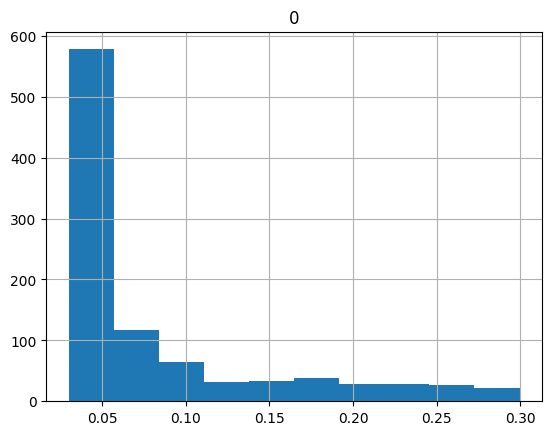

In [6]:
metab_features = metabolites.iloc[:, 27:].columns.tolist()
pd.DataFrame((metabolites[metab_features].isna().sum() / metabolites[metab_features].shape[0]).values).hist()
len(metab_features)

#### Metabolite dictionary

In [7]:
metab_dict = {'metabolite_35': 'S-1-pyrroline-5-carboxylate',
 'metabolite_50': 'spermidine',
 'metabolite_55': '1-methylnicotinamide',
 'metabolite_62': '12,13-DiHOME',
 'metabolite_93': 'alpha-ketoglutarate',
 'metabolite_98': 'kynurenate',
 'metabolite_111': '3-hydroxyisobutyrate',
 'metabolite_112': '3-hydroxy-3-methylglutarate',
 'metabolite_132': '3-phosphoglycerate',
 'metabolite_136': 'cholate',
 'metabolite_158': '5,6-dihydrothymine',
 'metabolite_171': 'hypoxanthine',
 'metabolite_179': '9,10-DiHOME',
 'metabolite_180': 'linoleate (18:2n6)',
 'metabolite_181': 'laurate (12:0)',
 'metabolite_182': 'quinolinate',
 'metabolite_189': 'N6,N6,N6-trimethyllysine',
 'metabolite_192': 'N-acetylputrescine',
 'metabolite_194': 'N-formylmethionine',
 'metabolite_197': 'S-adenosylhomocysteine (SAH)',
 'metabolite_207': "adenosine 3',5'-cyclic monophosphate (cAMP)",
 'metabolite_209': "adenosine 5'-monophosphate (AMP)",
 'metabolite_212': '5-methylthioadenosine (MTA)',
 'metabolite_229': 'arachidonate (20:4n6)',
 'metabolite_231': 'arginine',
 'metabolite_234': 'aspartate',
 'metabolite_235': '2-hydroxyphenylacetate',
 'metabolite_240': '3-(4-hydroxyphenyl)lactate',
 'metabolite_241': 'phenylpyruvate',
 'metabolite_244': 'beta-alanine',
 'metabolite_250': 'biliverdin',
 'metabolite_252': 'succinate',
 'metabolite_254': '3-hydroxybutyrate (BHBA)',
 'metabolite_266': 'cholesterol',
 'metabolite_267': 'choline phosphate',
 'metabolite_272': 'corticosterone',
 'metabolite_273': 'cortisone',
 'metabolite_275': 'creatinine',
 'metabolite_278': 'cysteinylglycine',
 'metabolite_279': 'cystine',
 'metabolite_297': 'sphingosine',
 'metabolite_302': 'deoxycholate',
 'metabolite_310': 'cystathionine',
 'metabolite_313': 'sphinganine',
 'metabolite_330': 'fumarate',
 'metabolite_331': 'gamma-glutamylglutamate',
 'metabolite_338': 'gluconate',
 'metabolite_339': 'glutarate (C5-DC)',
 'metabolite_340': 'glycine',
 'metabolite_342': 'glycocholate',
 'metabolite_344': 'guanidinoacetate',
 'metabolite_355': 'histidine',
 'metabolite_356': 'cortisol',
 'metabolite_358': 'hypotaurine',
 'metabolite_361': 'inosine',
 'metabolite_363': 'myo-inositol',
 'metabolite_376': 'isoleucine',
 'metabolite_391': 'citrulline',
 'metabolite_397': 'leucine',
 'metabolite_407': 'lysine',
 'metabolite_409': 'malate',
 'metabolite_415': 'methionine',
 'metabolite_424': 'palmitate (16:0)',
 'metabolite_432': 'nicotinamide',
 'metabolite_439': 'stearate (18:0)',
 'metabolite_444': 'ornithine',
 'metabolite_445': 'orotate',
 'metabolite_452': 'palmitoleate (16:1n7)',
 'metabolite_460': 'phenylalanine',
 'metabolite_461': 'phosphate',
 'metabolite_480': 'proline',
 'metabolite_482': 'lactate',
 'metabolite_491': 'pyridoxal',
 'metabolite_498': 'retinol (vitamin A)',
 'metabolite_501': 'salicylate',
 'metabolite_503': 'serine',
 'metabolite_504': 'serotonin',
 'metabolite_512': 'taurine',
 'metabolite_519': 'myristate (14:0)',
 'metabolite_533': 'urea',
 'metabolite_535': 'uridine',
 'metabolite_537': 'trans-urocanate',
 'metabolite_561': 'glutamate',
 'metabolite_563': 'glutamine',
 'metabolite_564': 'threonine',
 'metabolite_565': 'tryptophan',
 'metabolite_566': 'valine',
 'metabolite_572': 'glucose',
 'metabolite_796': 'alpha-ketobutyrate',
 'metabolite_798': 'adenosine',
 'metabolite_799': 'betaine',
 'metabolite_800': 'cysteine',
 'metabolite_803': 'mannose',
 'metabolite_806': 'dimethylglycine',
 'metabolite_811': 'alanine',
 'metabolite_815': 'tyrosine',
 'metabolite_821': 'pseudouridine',
 'metabolite_823': 'pyruvate',
 'metabolite_825': 'uracil',
 'metabolite_849': 'caffeine',
 'metabolite_878': 'fructose',
 'metabolite_880': 'adenine',
 'metabolite_888': 'caprate (10:0)',
 'metabolite_891': 'margarate (17:0)',
 'metabolite_892': 'nonadecanoate (19:0)',
 'metabolite_893': 'arachidate (20:0)',
 'metabolite_913': 'maltose',
 'metabolite_917': 'asparagine',
 'metabolite_922': 'N-stearoyl-sphinganine (d18:0/18:0)*',
 'metabolite_923': 'dihydroorotate',
 'metabolite_932': 'caprylate (8:0)',
 'metabolite_980': 'pentadecanoate (15:0)',
 'metabolite_1001': 'trans-4-hydroxyproline',
 'metabolite_1002': 'allantoin',
 'metabolite_1004': 'xanthine',
 'metabolite_1021': '5-oxoproline',
 'metabolite_1022': 'picolinate',
 'metabolite_1023': 'sarcosine',
 'metabolite_1024': 'pantothenate',
 'metabolite_1025': 'pipecolate',
 'metabolite_1026': 'phosphoethanolamine',
 'metabolite_1052': 'glycerate',
 'metabolite_1053': '3-ureidopropionate',
 'metabolite_1082': 'N-acetylleucine',
 'metabolite_1083': 'N-acetylmethionine',
 'metabolite_1084': 'N-acetylvaline',
 'metabolite_1087': 'erucate (22:1n9)',
 'metabolite_1090': 'bilirubin (Z,Z)',
 'metabolite_1094': 'thyroxine',
 'metabolite_1102': 'gamma-glutamyltyrosine',
 'metabolite_1105': 'alpha-tocopherol',
 'metabolite_1110': 'N-acetylalanine',
 'metabolite_1111': 'vanillylmandelate (VMA)',
 'metabolite_1113': '4-acetamidobutanoate',
 'metabolite_1114': '3-aminoisobutyrate',
 'metabolite_1124': 'citrate',
 'metabolite_1128': '2-aminobutyrate',
 'metabolite_1134': 'urate',
 'metabolite_1135': 'ursodeoxycholate',
 'metabolite_1137': 'oleoyl ethanolamide (18:1)',
 'metabolite_1140': 'gamma-glutamylglutamine',
 'metabolite_1141': '4-hydroxyphenylpyruvate',
 'metabolite_1162': 'N-acetylneuraminate',
 'metabolite_1221': 'creatine',
 'metabolite_1224': 'cys-gly, oxidized',
 'metabolite_1231': 'dihomo-linoleate (20:2n6)',
 'metabolite_1235': 'gamma-glutamylhistidine',
 'metabolite_1239': '2-hydroxystearate',
 'metabolite_1242': 'N1-methyladenosine',
 'metabolite_1254': 'glycerol',
 'metabolite_1256': 'choline',
 'metabolite_1268': 'gamma-glutamylleucine',
 'metabolite_1342': '3-methoxytyrosine',
 'metabolite_1442': 'beta-hydroxyisovalerate',
 'metabolite_1489': 'palmitoyl ethanolamide (16:0)',
 'metabolite_1518': 'N-palmitoyl-sphingosine (d18:1/16:0)',
 'metabolite_1526': '1-palmitoyl-2-oleoyl-GPE (16:0/18:1)',
 'metabolite_1528': '1-palmitoyl-2-linoleoyl-GPI (16:0/18:2)',
 'metabolite_1537': '1-palmitoyl-2-linoleoyl-GPC (16:0/18:2)',
 'metabolite_1538': 'stearoyl sphingomyelin (d18:1/18:0)',
 'metabolite_1539': '1-palmitoyl-2-oleoyl-GPC (16:0/18:1)',
 'metabolite_1547': 'N-stearoyl-sphingosine (d18:1/18:0)*',
 'metabolite_1628': 'glycochenodeoxycholate',
 'metabolite_1629': 'taurochenodeoxycholate',
 'metabolite_1648': 'taurocholate',
 'metabolite_1668': 'taurodeoxycholate',
 'metabolite_1869': '2-hydroxyhippurate (salicylurate)',
 'metabolite_2050': 'eicosapentaenoate (EPA; 20:5n3)',
 'metabolite_2051': 'methylsuccinate',
 'metabolite_2054': 'ethylmalonate',
 'metabolite_100000007': 'carnitine',
 'metabolite_100000008': 'benzoate',
 'metabolite_100000010': '3-phenylpropionate (hydrocinnamate)',
 'metabolite_100000014': 'hippurate',
 'metabolite_100000015': 'xanthurenate',
 'metabolite_100000036': '3-methyl-2-oxovalerate',
 'metabolite_100000039': 'methionine sulfoxide',
 'metabolite_100000042': '3-methylhistidine',
 'metabolite_100000054': '5-hydroxylysine',
 'metabolite_100000096': '4-guanidinobutanoate',
 'metabolite_100000257': 'glucuronate',
 'metabolite_100000263': 'imidazole lactate',
 'metabolite_100000265': 'kynurenine',
 'metabolite_100000269': 'glycerophosphorylcholine (GPC)',
 'metabolite_100000276': 'maltotriose',
 'metabolite_100000282': 'N-acetylglutamate',
 'metabolite_100000406': 'ribitol',
 'metabolite_100000436': 'glycodeoxycholate',
 'metabolite_100000437': 'theophylline',
 'metabolite_100000442': 'quinate',
 'metabolite_100000445': 'theobromine',
 'metabolite_100000447': 'gentisate',
 'metabolite_100000453': 'paraxanthine',
 'metabolite_100000463': 'indolelactate',
 'metabolite_100000467': '3-indoxyl sulfate',
 'metabolite_100000491': 'gamma-glutamylphenylalanine',
 'metabolite_100000551': '4-methyl-2-oxopentanoate',
 'metabolite_100000580': '1,5-anhydroglucitol (1,5-AG)',
 'metabolite_100000611': '1-palmityl-GPC (O-16:0)',
 'metabolite_100000616': '1-stearoyl-2-arachidonoyl-GPI (18:0/20:4)',
 'metabolite_100000626': 'sphingosine 1-phosphate',
 'metabolite_100000639': '1-stearoyl-2-oleoyl-GPS (18:0/18:1)',
 'metabolite_100000656': '1-stearoyl-GPI (18:0)',
 'metabolite_100000657': '1,2-dipalmitoyl-GPC (16:0/16:0)',
 'metabolite_100000665': 'docosahexaenoate (DHA; 22:6n3)',
 'metabolite_100000672': '1-myristoyl-2-palmitoyl-GPC (14:0/16:0)',
 'metabolite_100000706': 'alpha-hydroxyisocaproate',
 'metabolite_100000707': 'maleate',
 'metabolite_100000743': '2-hydroxyoctanoate',
 'metabolite_100000773': '3-hydroxyoctanoate',
 'metabolite_100000774': 'phenyllactate (PLA)',
 'metabolite_100000776': 'palmitoylcarnitine (C16)',
 'metabolite_100000781': 'hexanoylcarnitine (C6)',
 'metabolite_100000787': 'N-acetylaspartate (NAA)',
 'metabolite_100000792': 'dehydroepiandrosterone sulfate (DHEA-S)',
 'metabolite_100000802': 'acetylcarnitine (C2)',
 'metabolite_100000808': 'cysteine s-sulfate',
 'metabolite_100000827': '1-palmitoylglycerol (16:0)',
 'metabolite_100000840': 'tartronate (hydroxymalonate)',
 'metabolite_100000841': 'oxalate (ethanedioate)',
 'metabolite_100000846': 'erythritol',
 'metabolite_100000882': '3-hydroxymyristate',
 'metabolite_100000900': 'iminodiacetate (IDA)',
 'metabolite_100000924': '1-oleoylglycerol (18:1)',
 'metabolite_100000936': '3-methyl-2-oxobutyrate',
 'metabolite_100000961': 'homoarginine',
 'metabolite_100000963': 'homocitrulline',
 'metabolite_100000966': 'pyroglutamylglutamine',
 'metabolite_100000987': '2-linoleoylglycerol (18:2)',
 'metabolite_100000997': '3-hydroxydecanoate',
 'metabolite_100001002': 'EDTA',
 'metabolite_100001006': 'N-acetylglycine',
 'metabolite_100001007': 'ribonate',
 'metabolite_100001022': 'threonate',
 'metabolite_100001034': 'indoleacetate',
 'metabolite_100001040': '1-linoleoylglycerol (18:2)',
 'metabolite_100001051': '1-methylhistidine',
 'metabolite_100001054': 'butyrylcarnitine (C4)',
 'metabolite_100001055': 'isobutyrylcarnitine (C4)',
 'metabolite_100001073': 'androsterone sulfate',
 'metabolite_100001083': 'indolepropionate',
 'metabolite_100001092': "trigonelline (N'-methylnicotinate)",
 'metabolite_100001102': 'dodecanedioate (C12-DC)',
 'metabolite_100001104': 'N-acetyltyrosine',
 'metabolite_100001106': '1,3-dimethylurate',
 'metabolite_100001108': '3-methylxanthine',
 'metabolite_100001112': '3-hydroxylaurate',
 'metabolite_100001121': 'pyridoxate',
 'metabolite_100001126': 'gamma-glutamylvaline',
 'metabolite_100001132': 'pyroglutamylvaline',
 'metabolite_100001145': '3-hydroxysebacate',
 'metabolite_100001148': '5-hydroxyhexanoate',
 'metabolite_100001150': 'propionylglycine',
 'metabolite_100001162': 'propionylcarnitine (C3)',
 'metabolite_100001167': 'pro-hydroxy-pro',
 'metabolite_100001170': '3-hydroxy-2-ethylpropionate',
 'metabolite_100001178': '3-carboxy-4-methyl-5-propyl-2-furanpropanoate (CMPF)',
 'metabolite_100001181': 'docosapentaenoate (n3 DPA; 22:5n3)',
 'metabolite_100001182': 'docosadienoate (22:2n6)',
 'metabolite_100001193': 'adrenate (22:4n6)',
 'metabolite_100001197': '10-undecenoate (11:1n1)',
 'metabolite_100001198': 'myristoleate (14:1n5)',
 'metabolite_100001208': '1-methyl-4-imidazoleacetate',
 'metabolite_100001211': 'sebacate (C10-DC)',
 'metabolite_100001229': 'stearidonate (18:4n3)',
 'metabolite_100001232': '5-dodecenoate (12:1n7)',
 'metabolite_100001247': 'octanoylcarnitine (C8)',
 'metabolite_100001251': 'decanoylcarnitine (C10)',
 'metabolite_100001253': 'N-acetylglutamine',
 'metabolite_100001254': 'N-acetyltryptophan',
 'metabolite_100001256': 'N-acetylphenylalanine',
 'metabolite_100001262': 'gamma-glutamyl-epsilon-lysine',
 'metabolite_100001263': '1-palmitoyl-GPC (16:0)',
 'metabolite_100001264': '1-margaroyl-GPC (17:0)',
 'metabolite_100001266': 'N-acetylarginine',
 'metabolite_100001267': 'piperine',
 'metabolite_100001270': 'myristoylcarnitine (C14)',
 'metabolite_100001271': '1-stearoyl-GPC (18:0)',
 'metabolite_100001272': '1-oleoyl-GPC (18:1)',
 'metabolite_100001274': 'N-acetylthreonine',
 'metabolite_100001276': 'N-acetylisoleucine',
 'metabolite_100001277': 'nonadecenoate (19:1)',
 'metabolite_100001278': 'heptadecenoate (17:1)',
 'metabolite_100001287': 'epiandrosterone sulfate',
 'metabolite_100001293': 'N-acetylhistidine',
 'metabolite_100001294': 'gamma-glutamylglycine',
 'metabolite_100001295': 'gamma-glutamyltryptophan',
 'metabolite_100001296': 'stachydrine',
 'metabolite_100001300': 'alpha-hydroxyisovalerate',
 'metabolite_100001313': 'gamma-glutamylmethionine',
 'metabolite_100001314': 'gamma-glutamylthreonine',
 'metabolite_100001315': 'p-cresol sulfate',
 'metabolite_100001320': 'erythronate*',
 'metabolite_100001335': 'eicosenoate (20:1)',
 'metabolite_100001337': 'linolenate [alpha or gamma; (18:3n3 or 6)]',
 'metabolite_100001359': 'aconitate [cis or trans]',
 'metabolite_100001383': '1-myristoyl-GPC (14:0)',
 'metabolite_100001384': '1-arachidoyl-GPC (20:0)',
 'metabolite_100001391': 'stearoylcarnitine (C18)',
 'metabolite_100001392': 'laurylcarnitine (C12)',
 'metabolite_100001393': 'isovalerylcarnitine (C5)',
 'metabolite_100001395': '1-linoleoyl-GPC (18:2)',
 'metabolite_100001396': '7-methylxanthine',
 'metabolite_100001398': '3,7-dimethylurate',
 'metabolite_100001399': '1,7-dimethylurate',
 'metabolite_100001402': '5-acetylamino-6-formylamino-3-methyluracil',
 'metabolite_100001403': '5-acetylamino-6-amino-3-methyluracil',
 'metabolite_100001405': '1-methylxanthine',
 'metabolite_100001409': 'N1-methylinosine',
 'metabolite_100001412': 'N2,N2-dimethylguanosine',
 'metabolite_100001413': 'N4-acetylcytidine',
 'metabolite_100001415': 'N6-carbamoylthreonyladenosine',
 'metabolite_100001416': 'orotidine',
 'metabolite_100001417': 'phenylacetylglutamine',
 'metabolite_100001423': '4-hydroxyhippurate',
 'metabolite_100001425': '5,6-dihydrouridine',
 'metabolite_100001426': '3-(3-amino-3-carboxypropyl)uridine*',
 'metabolite_100001433': '1-arachidonylglycerol (20:4)',
 'metabolite_100001437': 'cysteine-glutathione disulfide',
 'metabolite_100001446': '5-methyluridine (ribothymidine)',
 'metabolite_100001452': 'isovalerylglycine',
 'metabolite_100001456': '7-methylguanine',
 'metabolite_100001461': '1-stearoyl-GPE (18:0)',
 'metabolite_100001468': 'N1-methyl-2-pyridone-5-carboxamide',
 'metabolite_100001485': 'gamma-glutamylisoleucine*',
 'metabolite_100001501': 'oleoylcarnitine (C18:1)',
 'metabolite_100001509': '2-methylbutyrylcarnitine (C5)',
 'metabolite_100001510': 'phenol sulfate',
 'metabolite_100001511': '1-palmitoleoyl-GPC (16:1)*',
 'metabolite_100001527': 'hexanoylglycine',
 'metabolite_100001540': '2-amino-4-cyanobutanoate',
 'metabolite_100001541': '2-hydroxy-3-methylvalerate',
 'metabolite_100001550': 'homostachydrine*',
 'metabolite_100001551': '1-arachidonoyl-GPC (20:4n6)*',
 'metabolite_100001552': '1-dihomo-linolenoyl-GPC (20:3n3 or n6)*',
 'metabolite_100001553': '1-dihomo-linoleoyl-GPC (20:2)*',
 'metabolite_100001554': '2-arachidonoyl-GPC (20:4)*',
 'metabolite_100001556': '2-oleoyl-GPC (18:1)*',
 'metabolite_100001557': '2-linoleoyl-GPC (18:2)*',
 'metabolite_100001562': '2-palmitoyl-GPC (16:0)*',
 'metabolite_100001563': '2-myristoyl-GPC (14:0)*',
 'metabolite_100001566': '1-docosahexaenoyl-GPC (22:6)*',
 'metabolite_100001567': '1-palmitoyl-GPE (16:0)',
 'metabolite_100001569': '1-oleoyl-GPE (18:1)',
 'metabolite_100001570': '1-linoleoyl-GPE (18:2)*',
 'metabolite_100001571': '1-arachidonoyl-GPE (20:4n6)*',
 'metabolite_100001577': 'N-acetylcitrulline',
 'metabolite_100001579': '2-hydroxypalmitate',
 'metabolite_100001580': 'docosapentaenoate (n6 DPA; 22:5n6)',
 'metabolite_100001586': 'gulonate*',
 'metabolite_100001590': 'isobutyrylglycine',
 'metabolite_100001593': 'glutarylcarnitine (C5-DC)',
 'metabolite_100001597': 'tiglylcarnitine (C5:1-DC)',
 'metabolite_100001604': 'hydroquinone sulfate',
 'metabolite_100001605': 'catechol sulfate',
 'metabolite_100001609': '7alpha-hydroxy-3-oxo-4-cholestenoate (7-Hoca)',
 'metabolite_100001613': 'tetradecanedioate (C14-DC)',
 'metabolite_100001614': 'hexadecanedioate (C16-DC)',
 'metabolite_100001620': 'glycerophosphoethanolamine',
 'metabolite_100001624': '3-(3-hydroxyphenyl)propionate',
 'metabolite_100001635': 'ectoine',
 'metabolite_100001651': '2-oleoyl-GPE (18:1)*',
 'metabolite_100001652': '2-palmitoyl-GPE (16:0)*',
 'metabolite_100001654': '1-arachidonoyl-GPI (20:4)*',
 'metabolite_100001655': '1-palmitoyl-GPI (16:0)',
 'metabolite_100001657': 'glycolithocholate sulfate*',
 'metabolite_100001658': 'taurolithocholate 3-sulfate',
 'metabolite_100001662': 'deoxycarnitine',
 'metabolite_100001664': 'N6-succinyladenosine',
 'metabolite_100001668': '1-ribosyl-imidazoleacetate*',
 'metabolite_100001674': '2-arachidonoyl-GPE (20:4)*',
 'metabolite_100001731': 'indoleacetylglutamine',
 'metabolite_100001733': 'hexanoylglutamine',
 'metabolite_100001734': 'N6-acetyllysine',
 'metabolite_100001739': 'dihomo-linolenate (20:3n3 or n6)',
 'metabolite_100001740': 'mannitol/sorbitol',
 'metabolite_100001743': 'tryptophan betaine',
 'metabolite_100001755': '4-vinylphenol sulfate',
 'metabolite_100001756': '4-ethylphenylsulfate',
 'metabolite_100001757': 'thymol sulfate',
 'metabolite_100001776': '2-linoleoyl-GPE (18:2)*',
 'metabolite_100001777': '1-oleoyl-GPI (18:1)',
 'metabolite_100001778': '1-linoleoyl-GPI (18:2)*',
 'metabolite_100001810': 'dimethylarginine (SDMA + ADMA)',
 'metabolite_100001851': 'N-acetylserine',
 'metabolite_100001856': '1-stearoyl-2-oleoyl-GPE (18:0/18:1)',
 'metabolite_100001868': '4-allylphenol sulfate',
 'metabolite_100001869': '1-stearoyl-2-arachidonoyl-GPC (18:0/20:4)',
 'metabolite_100001870': '1-palmitoyl-2-linoleoyl-GPE (16:0/18:2)',
 'metabolite_100001876': 'sphinganine-1-phosphate',
 'metabolite_100001882': 'glycosyl-N-stearoyl-sphingosine (d18:1/18:0)',
 'metabolite_100001948': 'succinylcarnitine (C4-DC)',
 'metabolite_100001950': 'bilirubin (E,E)*',
 'metabolite_100001951': 'bilirubin (E,Z or Z,E)*',
 'metabolite_100001956': 'N-methylproline',
 'metabolite_100001977': 'beta-cryptoxanthin',
 'metabolite_100001987': '5alpha-androstan-3beta,17beta-diol disulfate',
 'metabolite_100001988': '5alpha-pregnan-3beta,20alpha-diol disulfate',
 'metabolite_100001989': 'glycocholenate sulfate*',
 'metabolite_100001990': 'taurocholenate sulfate*',
 'metabolite_100001992': 'androstenediol (3beta,17beta) disulfate (1)',
 'metabolite_100001993': 'pregnenediol disulfate (C21H34O8S2)*',
 'metabolite_100001994': 'androstenediol (3beta,17beta) disulfate (2)',
 'metabolite_100001999': '21-hydroxypregnenolone disulfate',
 'metabolite_100002008': '5alpha-androstan-3alpha,17alpha-diol monosulfate',
 'metabolite_100002009': '5alpha-pregnan-3beta,20beta-diol monosulfate (1)',
 'metabolite_100002014': '5alpha-pregnan-3beta,20alpha-diol monosulfate (2)',
 'metabolite_100002018': '5alpha-androstan-3alpha,17beta-diol monosulfate (1)',
 'metabolite_100002021': '5alpha-androstan-3beta,17alpha-diol disulfate',
 'metabolite_100002024': '5alpha-androstan-3beta,17beta-diol monosulfate (2)',
 'metabolite_100002026': 'androstenediol (3alpha, 17alpha) monosulfate (2)',
 'metabolite_100002027': 'androstenediol (3alpha, 17alpha) monosulfate (3)',
 'metabolite_100002028': 'androstenediol (3beta,17beta) monosulfate (1)',
 'metabolite_100002029': 'androstenediol (3beta,17beta) monosulfate (2)',
 'metabolite_100002049': '4-hydroxycoumarin',
 'metabolite_100002060': '1-docosahexaenoyl-GPE (22:6)*',
 'metabolite_100002063': '1-docosapentaenoyl-GPC (22:5n3)*',
 'metabolite_100002067': 'pregnenediol sulfate (C21H34O5S)*',
 'metabolite_100002070': '2-hydroxyglutarate',
 'metabolite_100002094': 'gamma-CEHC',
 'metabolite_100002102': 'N-acetyl-beta-alanine',
 'metabolite_100002106': 'sphingomyelin (d18:1/18:1, d18:2/18:0)',
 'metabolite_100002107': 'palmitoyl sphingomyelin (d18:1/16:0)',
 'metabolite_100002122': '3-hydroxyhippurate',
 'metabolite_100002126': '16alpha-hydroxy DHEA 3-sulfate',
 'metabolite_100002129': 'pregnenolone sulfate',
 'metabolite_100002152': 'andro steroid monosulfate C19H28O6S (1)*',
 'metabolite_100002154': 'ergothioneine',
 'metabolite_100002171': '1-margaroyl-GPE (17:0)*',
 'metabolite_100002173': '1-pentadecanoyl-GPC (15:0)*',
 'metabolite_100002183': 'S-methylmethionine',
 'metabolite_100002185': 'indole-3-carboxylate',
 'metabolite_100002196': '13-HODE + 9-HODE',
 'metabolite_100002199': 'tridecenedioate (C13:1-DC)*',
 'metabolite_100002227': '4-cholesten-3-one',
 'metabolite_100002253': 'cinnamoylglycine',
 'metabolite_100002259': 'cis-4-decenoylcarnitine (C10:1)',
 'metabolite_100002293': 'phenylalanylphenylalanine',
 'metabolite_100002356': '(16 or 17)-methylstearate (a19:0 or i19:0)',
 'metabolite_100002417': '2,3-dihydroxyisovalerate',
 'metabolite_100002458': '3-methylglutaconate',
 'metabolite_100002488': 'isoursodeoxycholate',
 'metabolite_100002514': 'hydantoin-5-propionate',
 'metabolite_100002528': 'sulfate*',
 'metabolite_100002537': '4-hydroxy-2-oxoglutaric acid',
 'metabolite_100002749': 'S-methylcysteine',
 'metabolite_100002761': 'androsterone glucuronide',
 'metabolite_100002769': 'argininate*',
 'metabolite_100002784': '2-oxoarginine*',
 'metabolite_100002796': 'cis-4-decenoate (10:1n6)*',
 'metabolite_100002871': '1-adrenoyl-GPC (22:4)*',
 'metabolite_100002875': '1-(1-enyl-palmitoyl)-GPC (P-16:0)*',
 'metabolite_100002876': '1-(1-enyl-oleoyl)-GPC (P-18:1)*',
 'metabolite_100002910': '1-methyl-5-imidazoleacetate',
 'metabolite_100002911': 'glycoursodeoxycholate',
 'metabolite_100002927': 'S-methylcysteine sulfoxide',
 'metabolite_100002951': 'eicosanedioate (C20-DC)',
 'metabolite_100002952': 'docosadioate (C22-DC)',
 'metabolite_100002953': '16-hydroxypalmitate',
 'metabolite_100002989': 'oleoyl-linoleoyl-glycerol (18:1/18:2) [1]',
 'metabolite_100002990': 'oleoyl-linoleoyl-glycerol (18:1/18:2) [2]',
 'metabolite_100003000': '1-(1-enyl-palmitoyl)-GPE (P-16:0)*',
 'metabolite_100003001': '1-(1-enyl-stearoyl)-GPE (P-18:0)*',
 'metabolite_100003008': '2-stearoyl-GPI (18:0)*',
 'metabolite_100003119': 'N-oleoyltaurine',
 'metabolite_100003151': 'linoleoylcarnitine (C18:2)*',
 'metabolite_100003163': 'isoleucylalanine',
 'metabolite_100003169': 'isoleucylglycine',
 'metabolite_100003240': 'N-stearoyltaurine',
 'metabolite_100003260': 'carboxyethyl-GABA',
 'metabolite_100003271': 'beta-citrylglutamate',
 'metabolite_100003397': 'trimethylamine N-oxide',
 'metabolite_100003434': 'imidazole propionate',
 'metabolite_100003470': 'pregnanediol-3-glucuronide',
 'metabolite_100003473': 'alliin',
 'metabolite_100003594': 'phenylalanyltryptophan',
 'metabolite_100003686': 'N-palmitoylglycine',
 'metabolite_100003696': 'succinimide',
 'metabolite_100003901': '2-stearoyl-GPE (18:0)*',
 'metabolite_100003926': '(R)-3-hydroxybutyrylcarnitine',
 'metabolite_100004046': 'N-acetylcarnosine',
 'metabolite_100004054': 'margaroylcarnitine (C17)*',
 'metabolite_100004083': 'glycohyocholate',
 'metabolite_100004089': '2-hydroxydecanoate',
 'metabolite_100004111': '4-methylcatechol sulfate',
 'metabolite_100004112': '3-methyl catechol sulfate (1)',
 'metabolite_100004182': '3beta-hydroxy-5-cholenoate',
 'metabolite_100004208': 'guaiacol sulfate',
 'metabolite_100004227': '2-aminooctanoate',
 'metabolite_100004295': '2-piperidinone',
 'metabolite_100004299': 'N-acetyl-1-methylhistidine*',
 'metabolite_100004322': '2-aminophenol sulfate',
 'metabolite_100004328': 'sphingomyelin (d18:1/14:0, d16:1/16:0)*',
 'metabolite_100004329': 'sphingomyelin (d18:2/16:0, d18:1/16:1)*',
 'metabolite_100004499': '6-oxopiperidine-2-carboxylate',
 'metabolite_100004509': 'S-allylcysteine',
 'metabolite_100004523': 'N-delta-acetylornithine',
 'metabolite_100004541': 'acisoga',
 'metabolite_100004542': '2-aminoheptanoate',
 'metabolite_100004552': '1-eicosapentaenoyl-GPE (20:5)*',
 'metabolite_100004575': 'N2,N5-diacetylornithine',
 'metabolite_100004635': 'methionine sulfone',
 'metabolite_100004646': 'cyclo(ala-pro)',
 'metabolite_100005350': '1-linolenoyl-GPC (18:3)*',
 'metabolite_100005351': '1-eicosapentaenoyl-GPC (20:5)*',
 'metabolite_100005352': '1-eicosenoyl-GPC (20:1)*',
 'metabolite_100005367': 'N-acetylalliin',
 'metabolite_100005371': '1-dihomo-linolenoyl-GPE (20:3n3 or n6)*',
 'metabolite_100005372': '1-(1-enyl-oleoyl)-GPE (P-18:1)*',
 'metabolite_100005384': 'O-sulfo-tyrosine',
 'metabolite_100005403': 'etiocholanolone glucuronide',
 'metabolite_100005466': 'N-acetyltaurine',
 'metabolite_100005673': '1-docosapentaenoyl-GPC (22:5n6)*',
 'metabolite_100005714': '1-linolenoyl-GPE (18:3)*',
 'metabolite_100005717': '1-palmitoyl-GPG (16:0)*',
 'metabolite_100005834': '9-hydroxystearate',
 'metabolite_100005850': '3-methylglutarylcarnitine (2)',
 'metabolite_100005864': 'methyl glucopyranoside (alpha + beta)',
 'metabolite_100005985': 'sphingomyelin (d18:2/14:0, d18:1/14:1)*',
 'metabolite_100005986': 'sphingomyelin (d18:1/24:1, d18:2/24:0)*',
 'metabolite_100005996': 'octadecenedioylcarnitine (C18:1-DC)*',
 'metabolite_100006051': 'myristoleoylcarnitine/physeteroylcarnitine (C14:1)*',
 'metabolite_100006056': 'N-formylphenylalanine',
 'metabolite_100006065': 'cyclo(pro-val)',
 'metabolite_100006082': '4-hydroxychlorothalonil',
 'metabolite_100006092': 'tyramine O-sulfate',
 'metabolite_100006098': '3-hydroxypyridine sulfate',
 'metabolite_100006108': 'phenylacetylcarnitine',
 'metabolite_100006115': 'arabonate/xylonate',
 'metabolite_100006116': 'methyl-4-hydroxybenzoate sulfate',
 'metabolite_100006121': '1-dihomo-linolenylglycerol (20:3n3 or n6)',
 'metabolite_100006129': 'vanillactate',
 'metabolite_100006171': 'eugenol sulfate',
 'metabolite_100006191': 'p-cresol glucuronide*',
 'metabolite_100006260': '6-hydroxyindole sulfate',
 'metabolite_100006290': 'sphingomyelin (d18:1/20:0, d16:1/22:0)*',
 'metabolite_100006292': 'sphingomyelin (d18:1/20:1, d18:2/20:0)*',
 'metabolite_100006293': 'sphingomyelin (d18:1/20:2, d18:2/20:1, d16:1/22:2)*',
 'metabolite_100006294': 'behenoyl sphingomyelin (d18:1/22:0)*',
 'metabolite_100006295': 'sphingomyelin (d18:1/22:1, d18:2/22:0, d16:1/24:1)*',
 'metabolite_100006296': 'sphingomyelin (d18:1/22:2, d18:2/22:1, d16:1/24:2)*',
 'metabolite_100006298': 'lignoceroyl sphingomyelin (d18:1/24:0)',
 'metabolite_100006314': 'sphingomyelin (d17:1/16:0, d18:1/15:0, d16:1/17:0)*',
 'metabolite_100006361': 'dopamine 3-O-sulfate',
 'metabolite_100006367': '3-hydroxyhexanoate',
 'metabolite_100006370': '3beta-hydroxy-5-cholestenoate',
 'metabolite_100006374': '1,2,3-benzenetriol sulfate (2)',
 'metabolite_100006375': '3-methoxycatechol sulfate (1)',
 'metabolite_100006379': 'C-glycosyltryptophan',
 'metabolite_100006430': 'arabitol/xylitol',
 'metabolite_100006435': 'N-acetylglucosamine/N-acetylgalactosamine',
 'metabolite_100006614': 'adipoylcarnitine (C6-DC)',
 'metabolite_100006620': 'nonanoylcarnitine (C9)',
 'metabolite_100006641': 'glycochenodeoxycholate 3-sulfate',
 'metabolite_100006642': 'glycodeoxycholate 3-sulfate',
 'metabolite_100006644': 'taurodeoxycholic acid 3-sulfate',
 'metabolite_100006651': 'trans-3,4-methyleneheptanoate',
 'metabolite_100006726': 'linoleoyl ethanolamide (18:2)',
 'metabolite_100008903': '1,2-dilinoleoyl-GPC (18:2/18:2)',
 'metabolite_100008904': '1-stearoyl-2-oleoyl-GPC (18:0/18:1)',
 'metabolite_100008914': '1-palmitoyl-2-arachidonoyl-GPC (16:0/20:4n6)',
 'metabolite_100008915': '1-palmitoyl-2-docosahexaenoyl-GPC (16:0/22:6)',
 'metabolite_100008916': '1-stearoyl-2-docosahexaenoyl-GPC (18:0/22:6)',
 'metabolite_100008917': '1-(1-enyl-stearoyl)-2-oleoyl-GPC (P-18:0/18:1)',
 'metabolite_100008918': '1-(1-enyl-stearoyl)-2-arachidonoyl-GPC (P-18:0/20:4)',
 'metabolite_100008919': '1-(1-enyl-stearoyl)-2-oleoyl-GPE (P-18:0/18:1)',
 'metabolite_100008920': 'sphingomyelin (d18:1/17:0, d17:1/18:0, d19:1/16:0)',
 'metabolite_100008921': '1-palmitoyl-2-stearoyl-GPC (16:0/18:0)',
 'metabolite_100008928': '2-hydroxybutyrate/2-hydroxyisobutyrate',
 'metabolite_100008930': 'oleate/vaccenate (18:1)',
 'metabolite_100008939': 'isoleucylleucine/leucylisoleucine',
 'metabolite_100008951': 'leucylphenylalanine/isoleucylphenylalanine',
 'metabolite_100008952': '1-palmitoleoylglycerol (16:1)*',
 'metabolite_100008954': 'palmitoyl dihydrosphingomyelin (d18:0/16:0)*',
 'metabolite_100008955': 'tricosanoyl sphingomyelin (d18:1/23:0)*',
 'metabolite_100008956': 'sphingomyelin (d18:2/23:0, d18:1/23:1, d17:1/24:1)*',
 'metabolite_100008957': 'sphingomyelin (d18:2/24:1, d18:1/24:2)*',
 'metabolite_100008976': '1-stearoyl-2-linoleoyl-GPE (18:0/18:2)*',
 'metabolite_100008977': '1-stearoyl-2-arachidonoyl-GPE (18:0/20:4)',
 'metabolite_100008980': '1-stearoyl-2-linoleoyl-GPC (18:0/18:2)*',
 'metabolite_100008984': '1-palmitoyl-2-palmitoleoyl-GPC (16:0/16:1)*',
 'metabolite_100008989': '1-palmitoyl-2-eicosapentaenoyl-GPC (16:0/20:5)*',
 'metabolite_100008990': '1-palmitoyl-2-arachidonoyl-GPE (16:0/20:4)*',
 'metabolite_100008991': '1-palmitoyl-2-docosahexaenoyl-GPE (16:0/22:6)*',
 'metabolite_100008992': '1-stearoyl-2-docosahexaenoyl-GPE (18:0/22:6)*',
 'metabolite_100008993': '1-palmitoyl-2-arachidonoyl-GPI (16:0/20:4)*',
 'metabolite_100008994': '1-stearoyl-2-linoleoyl-GPI (18:0/18:2)',
 'metabolite_100008998': 'gamma-tocopherol/beta-tocopherol',
 'metabolite_100008999': '1-(1-enyl-stearoyl)-2-arachidonoyl-GPE (P-18:0/20:4)*',
 'metabolite_100009000': '1-(1-enyl-palmitoyl)-2-docosahexaenoyl-GPE (P-16:0/22:6)*',
 'metabolite_100009002': '1-(1-enyl-palmitoyl)-2-arachidonoyl-GPE (P-16:0/20:4)*',
 'metabolite_100009004': '1-(1-enyl-stearoyl)-2-docosahexaenoyl-GPE (P-18:0/22:6)*',
 'metabolite_100009005': '1-(1-enyl-palmitoyl)-2-oleoyl-GPE (P-16:0/18:1)*',
 'metabolite_100009006': '1-(1-enyl-palmitoyl)-2-dihomo-linolenoyl-GPC (P-16:0/20:3n3 or n6)*',
 'metabolite_100009007': '1-(1-enyl-palmitoyl)-2-oleoyl-GPC (P-16:0/18:1)*',
 'metabolite_100009008': '1-(1-enyl-palmitoyl)-2-docosahexaenoyl-GPC (P-16:0/22:6)*',
 'metabolite_100009009': '1-(1-enyl-palmitoyl)-2-linoleoyl-GPC (P-16:0/18:2)*',
 'metabolite_100009014': '1-(1-enyl-palmitoyl)-2-arachidonoyl-GPC (P-16:0/20:4)*',
 'metabolite_100009015': '1-(1-enyl-stearoyl)-2-docosahexaenoyl-GPC (P-18:0/22:6)*',
 'metabolite_100009019': '1-stearyl-2-arachidonoyl-GPC (O-18:0/20:4)*',
 'metabolite_100009020': '1-palmityl-2-oleoyl-GPC (O-16:0/18:1)*',
 'metabolite_100009021': '1-palmityl-2-arachidonoyl-GPC (O-16:0/20:4)*',
 'metabolite_100009025': 'sphingomyelin (d18:1/21:0, d17:1/22:0, d16:1/23:0)*',
 'metabolite_100009026': 'behenoyl dihydrosphingomyelin (d18:0/22:0)*',
 'metabolite_100009027': 'sphingomyelin (d18:0/18:0, d19:0/17:0)*',
 'metabolite_100009028': 'N-palmitoyl-sphinganine (d18:0/16:0)',
 'metabolite_100009030': 'lactosyl-N-palmitoyl-sphingosine (d18:1/16:0)',
 'metabolite_100009035': '1-pentadecanoyl-2-linoleoyl-GPC (15:0/18:2)*',
 'metabolite_100009036': '1-margaroyl-2-oleoyl-GPC (17:0/18:1)*',
 'metabolite_100009037': '1-margaroyl-2-linoleoyl-GPC (17:0/18:2)*',
 'metabolite_100009038': 'myristoyl dihydrosphingomyelin (d18:0/14:0)*',
 'metabolite_100009051': '1-stearoyl-2-dihomo-linolenoyl-GPC (18:0/20:3n3 or n6)*',
 'metabolite_100009052': 'palmitoyl-linoleoyl-glycerol (16:0/18:2) [1]*',
 'metabolite_100009055': 'palmitoyl-linoleoyl-glycerol (16:0/18:2) [2]*',
 'metabolite_100009066': '1-palmitoyl-2-oleoyl-GPI (16:0/18:1)*',
 'metabolite_100009067': '1-stearoyl-2-docosahexaenoyl-GPI (18:0/22:6)*',
 'metabolite_100009069': '1-(1-enyl-palmitoyl)-2-linoleoyl-GPE (P-16:0/18:2)*',
 'metabolite_100009078': '1-oleoyl-2-linoleoyl-GPE (18:1/18:2)*',
 'metabolite_100009082': '1-linoleoyl-GPA (18:2)*',
 'metabolite_100009122': '1-pentadecanoyl-2-arachidonoyl-GPC (15:0/20:4)*',
 'metabolite_100009123': '1-pentadecanoyl-2-docosahexaenoyl-GPC (15:0/22:6)*',
 'metabolite_100009124': '1-margaroyl-2-arachidonoyl-GPC (17:0/20:4)*',
 'metabolite_100009125': '1-margaroyl-2-docosahexaenoyl-GPC (17:0/22:6)*',
 'metabolite_100009126': '1-arachidoyl-2-arachidonoyl-GPC (20:0/20:4)*',
 'metabolite_100009130': '1-oleoyl-2-docosahexaenoyl-GPC (18:1/22:6)*',
 'metabolite_100009132': '1-linoleoyl-2-docosahexaenoyl-GPC (18:2/22:6)*',
 'metabolite_100009134': '1-palmityl-2-linoleoyl-GPC (O-16:0/18:2)*',
 'metabolite_100009135': '1-(1-enyl-stearoyl)-2-linoleoyl-GPC (P-18:0/18:2)*',
 'metabolite_100009138': '1-myristoyl-2-linoleoyl-GPC (14:0/18:2)*',
 'metabolite_100009139': '1-myristoyl-2-arachidonoyl-GPC (14:0/20:4)*',
 'metabolite_100009140': '1-myristoyl-2-docosahexaenoyl-GPC (14:0/22:6)*',
 'metabolite_100009141': '1-stearoyl-2-docosapentaenoyl-GPC (18:0/22:5n3)*',
 'metabolite_100009142': '1-stearoyl-2-docosapentaenoyl-GPC (18:0/22:5n6)*',
 'metabolite_100009143': '1-palmitoyl-2-adrenoyl-GPC (16:0/22:4)*',
 'metabolite_100009146': '1-stearoyl-2-adrenoyl-GPC (18:0/22:4)*',
 'metabolite_100009147': '1-stearyl-GPC (O-18:0)*',
 'metabolite_100009148': '1-oleoyl-2-dihomo-linolenoyl-GPC (18:1/20:3n3 or n6)*',
 'metabolite_100009160': '1-(1-enyl-palmitoyl)-2-palmitoleoyl-GPC (P-16:0/16:1)*',
 'metabolite_100009161': '1-(1-enyl-palmitoyl)-2-myristoyl-GPC (P-16:0/14:0)*',
 'metabolite_100009162': '1-(1-enyl-palmitoyl)-2-palmitoyl-GPC (P-16:0/16:0)*',
 'metabolite_100009166': 'phosphatidylcholine (16:0/22:5n3, 18:1/20:4)*',
 'metabolite_100009181': '1-stearoyl-2-oleoyl-GPI (18:0/18:1)*',
 'metabolite_100009184': '1-stearoyl-2-dihomo-linolenoyl-GPI (18:0/20:3n3 or n6)*',
 'metabolite_100009209': '1-palmitoyl-2-eicosapentaenoyl-GPE (16:0/20:5)*',
 'metabolite_100009215': '1-stearoyl-2-dihomo-linolenoyl-GPE (18:0/20:3n3 or n6)*',
 'metabolite_100009219': '1-oleoyl-2-arachidonoyl-GPE (18:1/20:4)*',
 'metabolite_100009225': '1-(1-enyl-stearoyl)-2-linoleoyl-GPE (P-18:0/18:2)*',
 'metabolite_100009227': '1-linoleoyl-GPG (18:2)*',
 'metabolite_100009232': 'thioproline',
 'metabolite_100009233': 'palmitoylcholine',
 'metabolite_100009264': 'glycochenodeoxycholate glucuronide (1)',
 'metabolite_100009271': '(S)-3-hydroxybutyrylcarnitine',
 'metabolite_100009272': 'glycosyl-N-palmitoyl-sphingosine (d18:1/16:0)',
 'metabolite_100009275': 'methylsuccinoylcarnitine',
 'metabolite_100009331': 'oleoylcholine',
 'metabolite_100009332': 'arachidonoylcholine',
 'metabolite_100009333': 'docosahexaenoylcholine',
 'metabolite_100009335': 'dihomo-linolenoyl-choline',
 'metabolite_100009343': '1-linoleoyl-2-linolenoyl-GPC (18:2/18:3)*',
 'metabolite_100009345': '1-palmitoleoyl-2-linolenoyl-GPC (16:1/18:3)*',
 'metabolite_100009346': 'phosphatidylcholine (14:0/14:0, 16:0/12:0)',
 'metabolite_100009347': 'phosphatidylcholine (15:0/18:1, 17:0/16:1, 16:0/17:1)*',
 'metabolite_100009350': 'phosphatidylcholine (18:1/20:2, 18:2/20:1)*',
 'metabolite_100009364': 'phosphatidylcholine (18:0/20:2, 20:0/18:2)*',
 'metabolite_100009376': '1-(1-enyl-oleoyl)-2-docosahexaenoyl-GPE (P-18:1/22:6)*',
 'metabolite_100009378': '1-(1-enyl-stearoyl)-2-dihomo-linolenoyl-GPE (P-18:0/20:3n3 or n6)*',
 'metabolite_100009394': 'hexadecadienoate (16:2n6)',
 'metabolite_100009406': 'palmitoleoylcarnitine (C16:1)*',
 'metabolite_100009407': 'pimeloylcarnitine/3-methyladipoylcarnitine (C7-DC)',
 'metabolite_100010850': '4-hydroxyphenylacetylglutamine',
 'metabolite_100010869': '2,3-dihydroxy-2-methylbutyrate',
 'metabolite_100010895': "2'-O-methylcytidine",
 'metabolite_100010896': "2'-O-methyluridine",
 'metabolite_100010901': 'gamma-glutamyl-alpha-lysine',
 'metabolite_100010916': 'palmitoyl-oleoyl-glycerol (16:0/18:1) [1]*',
 'metabolite_100010917': 'palmitoyl-oleoyl-glycerol (16:0/18:1) [2]*',
 'metabolite_100010918': 'oleoyl-oleoyl-glycerol (18:1/18:1) [1]*',
 'metabolite_100010919': 'oleoyl-oleoyl-glycerol (18:1/18:1) [2]*',
 'metabolite_100010922': 'linoleoyl-arachidonoyl-glycerol (18:2/20:4) [1]*',
 'metabolite_100010925': 'palmitoyl-arachidonoyl-glycerol (16:0/20:4) [2]*',
 'metabolite_100010927': 'linoleoyl-linolenoyl-glycerol (18:2/18:3) [2]*',
 'metabolite_100010930': 'palmitoleoyl-linoleoyl-glycerol (16:1/18:2) [1]*',
 'metabolite_100010935': 'diacylglycerol (14:0/18:1, 16:0/16:1) [2]*',
 'metabolite_100010936': 'oleoyl-arachidonoyl-glycerol (18:1/20:4) [1]*',
 'metabolite_100010937': 'oleoyl-arachidonoyl-glycerol (18:1/20:4) [2]*',
 'metabolite_100010940': 'diacylglycerol (16:1/18:2 [2], 16:0/18:3 [1])*',
 'metabolite_100010941': 'linoleoyl-linoleoyl-glycerol (18:2/18:2) [1]*',
 'metabolite_100010949': 'stearoyl-arachidonoyl-glycerol (18:0/20:4) [1]*',
 'metabolite_100010950': 'stearoyl-arachidonoyl-glycerol (18:0/20:4) [2]*',
 'metabolite_100010955': 'perfluorooctanesulfonate (PFOS)',
 'metabolite_100010966': '1-palmityl-2-stearoyl-GPC (O-16:0/18:0)*',
 'metabolite_100015586': '1-palmityl-2-palmitoyl-GPC (O-16:0/16:0)*',
 'metabolite_100015587': '1-stearyl-2-docosapentaenoyl-GPC (O-18:0/22:5n3)*',
 'metabolite_100015592': '1-stearoyl-2-docosapentaenoyl-GPE (18:0/22:5n3)*',
 'metabolite_100015593': '1-stearoyl-2-docosapentaenoyl-GPE (18:0/22:5n6)*',
 'metabolite_100015594': '1-stearoyl-2-adrenoyl-GPE (18:0/22:4)*',
 'metabolite_100015596': '1-(1-enyl-stearoyl)-2-docosapentaenoyl-GPE (P-18:0/22:5n3)*',
 'metabolite_100015618': 'palmitoyl-docosahexaenoyl-glycerol (16:0/22:6) [1]*',
 'metabolite_100015620': 'lactosyl-N-nervonoyl-sphingosine (d18:1/24:1)*',
 'metabolite_100015624': 'N-behenoyl-sphingadienine (d18:2/22:0)*',
 'metabolite_100015625': 'glycosyl-N-behenoyl-sphingadienine (d18:2/22:0)*',
 'metabolite_100015681': 'palmitoleoyl-arachidonoyl-glycerol (16:1/20:4) [2]*',
 'metabolite_100015683': 'myristoyl-linoleoyl-glycerol (14:0/18:2) [1]*',
 'metabolite_100015687': 'phosphatidylethanolamine (P-18:1/20:4, P-16:0/22:5n3)*',
 'metabolite_100015689': '1-palmitoyl-2-(hydroxylinoleoyl)-GPC (16:0/18:2(OH))*',
 'metabolite_100015727': 'ceramide (d16:1/24:1, d18:1/22:1)*',
 'metabolite_100015735': 'ceramide (d18:1/14:0, d16:1/16:0)*',
 'metabolite_100015737': 'ceramide (d18:1/17:0, d17:1/18:0)*',
 'metabolite_100015744': 'ceramide (d18:2/24:1, d18:1/24:2)*',
 'metabolite_100015745': 'glycosyl ceramide (d18:2/24:1, d18:1/24:2)*',
 'metabolite_100015755': 'ceramide (d18:1/20:0, d16:1/22:0, d20:1/18:0)*',
 'metabolite_100015759': 'stearoylcholine*',
 'metabolite_100015760': 'linoleoylcholine*',
 'metabolite_100015786': 'sphingomyelin (d18:0/20:0, d16:0/22:0)*',
 'metabolite_100015787': 'sphingomyelin (d18:1/19:0, d19:1/18:0)*',
 'metabolite_100015788': 'sphingomyelin (d18:2/18:1, d18:1/18:2)*',
 'metabolite_100015789': 'sphingomyelin (d18:2/24:2)*',
 'metabolite_100015790': 'sphingomyelin (d18:2/21:0, d16:2/23:0)*',
 'metabolite_100015791': 'sphingomyelin (d18:2/23:1)*',
 'metabolite_100015792': 'sphingomyelin (d18:1/25:0, d19:0/24:1, d20:1/23:0, d19:1/24:0)*',
 'metabolite_100015793': 'sphingomyelin (d17:2/16:0, d18:2/15:0)*',
 'metabolite_100015831': 'linolenoylcarnitine (C18:3)*',
 'metabolite_100015832': 'behenoylcarnitine (C22)*',
 'metabolite_100015833': 'arachidoylcarnitine (C20)*',
 'metabolite_100015834': 'lignoceroylcarnitine (C24)*',
 'metabolite_100015835': 'cerotoylcarnitine (C26)*',
 'metabolite_100015836': 'ximenoylcarnitine (C26:1)*',
 'metabolite_100015837': 'arachidonoylcarnitine (C20:4)',
 'metabolite_100015838': 'eicosenoylcarnitine (C20:1)*',
 'metabolite_100015839': 'dihomo-linoleoylcarnitine (C20:2)*',
 'metabolite_100015840': 'dihomo-linolenoylcarnitine (C20:3n3 or 6)*',
 'metabolite_100015845': 'docosahexaenoylcarnitine (C22:6)*',
 'metabolite_100015846': 'nervonoylcarnitine (C24:1)*',
 'metabolite_100015850': 'adrenoylcarnitine (C22:4)*',
 'metabolite_100015962': 'N,N,N-trimethyl-5-aminovalerate',
 'metabolite_100015965': 'ethyl alpha-glucopyranoside',
 'metabolite_100015966': 'carotene diol (1)',
 'metabolite_100015967': 'carotene diol (2)',
 'metabolite_100015968': 'carotene diol (3)',
 'metabolite_100015971': 'cortolone glucuronide (1)',
 'metabolite_100016038': '(N(1) + N(8))-acetylspermidine',
 'metabolite_100016069': '5-dodecenoylcarnitine (C12:1)',
 'metabolite_100016110': '2-butenoylglycine',
 'metabolite_100019794': 'hydroxy-CMPF*',
 'metabolite_100019884': 'trans-2-hexenoylglycine',
 'metabolite_100019972': 'dodecenedioate (C12:1-DC)*',
 'metabolite_100019975': 'hexadecenedioate (C16:1-DC)*',
 'metabolite_100019978': 'octadecenedioate (C18:1-DC)',
 'metabolite_100019982': 'octadecadienedioate (C18:2-DC)*',
 'metabolite_100020004': '3-carboxy-4-methyl-5-pentyl-2-furanpropionate (3-CMPFP)**',
 'metabolite_100020204': 'N-acetyl-2-aminooctanoate*',
 'metabolite_100020205': 'hydroxyasparagine**',
 'metabolite_100020208': 'perfluorooctanoate (PFOA)',
 'metabolite_100020214': 'glyco-beta-muricholate**',
 'metabolite_100020219': '3-formylindole',
 'metabolite_100020234': 'pyroglutamylleucine*',
 'metabolite_100020241': 'gamma-glutamylcitrulline*',
 'metabolite_100020253': 'glycine conjugate of C10H12O2*',
 'metabolite_100020254': 'glycine conjugate of C10H14O2 (1)*',
 'metabolite_100020259': 'glutamine conjugate of C7H12O2*',
 'metabolite_100020261': 'glutamine conjugate of C6H10O2 (1)*',
 'metabolite_100020262': 'glutamine conjugate of C6H10O2 (2)*',
 'metabolite_100020343': 'tetradecadienoate (14:2)*',
 'metabolite_100020361': '3-amino-2-piperidone',
 'metabolite_100020371': 'N,N-dimethylalanine',
 'metabolite_100020372': '3-indoleglyoxylic acid',
 'metabolite_100020377': 'ethyl beta-glucopyranoside',
 'metabolite_100020378': '2-hydroxysebacate',
 'metabolite_100020409': 'ascorbic acid 3-sulfate*',
 'metabolite_100020414': '6-bromotryptophan',
 'metabolite_100022482': 'N-lactoyl phenylalanine',
 'metabolite_100022485': 'N-lactoyl valine',
 'metabolite_100022480': 'N-lactoyl leucine',
 'metabolite_100022479': 'N-lactoyl isoleucine',
 'metabolite_100020478': 'dodecadienoate (12:2)*',
 'metabolite_100020487': 'N-acetyl-isoputreanine',
 'metabolite_100020491': 'glucuronide of piperine metabolite C17H21NO3 (3)*',
 'metabolite_100020492': 'glucuronide of piperine metabolite C17H21NO3 (4)*',
 'metabolite_100020493': 'glucuronide of piperine metabolite C17H21NO3 (5)*',
 'metabolite_100020496': 'sulfate of piperine metabolite C16H19NO3 (2)*',
 'metabolite_100020497': 'sulfate of piperine metabolite C16H19NO3 (3)*',
 'metabolite_100020502': 'sulfate of piperine metabolite C18H21NO3 (1)*',
 'metabolite_100020515': '2-naphthol sulfate',
 'metabolite_100020536': '4-ethylcatechol sulfate',
 'metabolite_100020541': '11beta-hydroxyandrosterone glucuronide',
 'metabolite_100020550': 'deoxycholic acid glucuronide',
 'metabolite_100020578': '4-allylcatechol sulfate',
 'metabolite_100020631': '4-methylhexanoylglutamine',
 'metabolite_100020823': 'lithocholate sulfate (1)',
 'metabolite_100020833': '2-ketocaprylate',
 'metabolite_100020893': '2,3-dihydroxy-5-methylthio-4-pentenoate (DMTPA)*',
 'metabolite_100021000': 'hydroxypalmitoyl sphingomyelin (d18:1/16:0(OH))**',
 'metabolite_100021015': 'branched-chain fatty acid 18:0 (2)**',
 'metabolite_100021100': 'tetradecadienedioate (C14:2-DC)*',
 'metabolite_100021104': 'pregnenetriol disulfate*',
 'metabolite_100021105': 'eicosenedioate (C20:1-DC)*',
 'metabolite_100021123': 'hydroxy-N6,N6,N6-trimethyllysine*',
 'metabolite_100021131': 'undecenoylcarnitine (C11:1)',
 'metabolite_100021162': 'palmitoyl-sphingosine-phosphoethanolamine (d18:1/16:0)',
 'metabolite_100021208': '4-vinylcatechol sulfate',
 'metabolite_100021324': '3,5-dichloro-2,6-dihydroxybenzoic acid',
 'metabolite_100021329': '(S)-a-amino-omega-caprolactam',
 'metabolite_100021331': 'metabolonic lactone sulfate',
 'metabolite_100021374': 'branched chain 14:0 dicarboxylic acid**',
 'metabolite_100021502': '(2 or 3)-decenoate (10:1n7 or n8)',
 'metabolite_100021666': 'branched-chain, straight-chain, or cyclopropyl 10:1 fatty acid (1)*',
 'metabolite_100021707': '3-bromo-5-chloro-2,6-dihydroxybenzoic acid*',
 'metabolite_100021709': 'branched-chain, straight-chain, or cyclopropyl 12:1 fatty acid*',
 'metabolite_100021711': 'decadienedioic acid (C10:2-DC)**',
 'metabolite_100021712': 'deoxycholic acid 12-sulfate*',
 'metabolite_100021727': 'cis-3,4-methyleneheptanoate',
 'metabolite_100021728': 'cis-3,4-methyleneheptanoylcarnitine',
 'metabolite_100021760': 'N-acetyl-2-aminoadipate',
 'metabolite_100021784': '4-chlorobenzoic acid',
 'metabolite_100021918': '2,4-di-tert-butylphenol',
 'metabolite_100021990': '3-hydroxyoctanoylcarnitine (1)',
 'metabolite_100021992': 'cis-3,4-methyleneheptanoylglycine',
 'metabolite_100022003': 'bilirubin degradation product, C16H18N2O5 (1)**',
 'metabolite_100022004': 'bilirubin degradation product, C16H18N2O5 (2)**',
 'metabolite_100022005': 'bilirubin degradation product, C17H18N2O4 (1)**',
 'metabolite_100022006': 'bilirubin degradation product, C17H18N2O4 (2)**',
 'metabolite_100022007': 'bilirubin degradation product, C17H18N2O4 (3)**',
 'metabolite_100022008': 'bilirubin degradation product, C17H20N2O5 (1)**',
 'metabolite_100022009': 'bilirubin degradation product, C17H20N2O5 (2)**',
 'metabolite_100022013': 'tetrahydrocortisol glucuronide',
 'metabolite_100022041': 'N,N-dimethyl-pro-pro',
 'metabolite_100022120': 'oxindolylalanine',
 'metabolite_100022127': 'tetrahydrocortisone glucuronide (5)',
 'metabolite_999932698': 'X - 11381',
 'metabolite_999933132': 'X - 11787',
 'metabolite_999933140': 'X - 11795',
 'metabolite_999946259': 'X - 21258',
 'metabolite_999946261': 'X - 19438',
 'metabolite_999946266': 'X - 15486',
 'metabolite_999946283': 'X - 15461',
 'metabolite_999946294': 'X - 21285',
 'metabolite_999946295': 'X - 21286',
 'metabolite_999946354': 'X - 21310',
 'metabolite_999946355': 'X - 09789',
 'metabolite_999946363': 'X - 21319',
 'metabolite_999946364': 'X - 12847',
 'metabolite_999946384': 'X - 21339',
 'metabolite_999946390': 'X - 11308',
 'metabolite_999946398': 'X - 21353',
 'metabolite_999946409': 'X - 21364',
 'metabolite_999946417': 'X - 13866',
 'metabolite_999946428': 'X - 21383',
 'metabolite_999946455': 'X - 21410',
 'metabolite_999946460': 'X - 11444',
 'metabolite_999946466': 'X - 11843',
 'metabolite_999946486': 'X - 21441',
 'metabolite_999946487': 'X - 21442',
 'metabolite_999946488': 'X - 11847',
 'metabolite_999946507': 'X - 11850',
 'metabolite_999946510': 'X - 12544',
 'metabolite_999946511': 'X - 16938',
 'metabolite_999946512': 'X - 21467',
 'metabolite_999946515': 'X - 21470',
 'metabolite_999946516': 'X - 21471',
 'metabolite_999946521': 'X - 11852',
 'metabolite_999946590': 'X - 07765',
 'metabolite_999946592': 'X - 11299',
 'metabolite_999946594': 'X - 11372',
 'metabolite_999946595': 'X - 11378',
 'metabolite_999946601': 'X - 11470',
 'metabolite_999946602': 'X - 11478',
 'metabolite_999946607': 'X - 11849',
 'metabolite_999946608': 'X - 11880',
 'metabolite_999946610': 'X - 12007',
 'metabolite_999946613': 'X - 12216',
 'metabolite_999946616': 'X - 12411',
 'metabolite_999946620': 'X - 12462',
 'metabolite_999946623': 'X - 12729',
 'metabolite_999946624': 'X - 12798',
 'metabolite_999946627': 'X - 12740',
 'metabolite_999946632': 'X - 14056',
 'metabolite_999946633': 'X - 12844',
 'metabolite_999946636': 'X - 12849',
 'metabolite_999946639': 'X - 12851',
 'metabolite_999946645': 'X - 13728',
 'metabolite_999946646': 'X - 13835',
 'metabolite_999946657': 'X - 14939',
 'metabolite_999946666': 'X - 15728',
 'metabolite_999946673': 'X - 16576',
 'metabolite_999946674': 'X - 21607',
 'metabolite_999946681': 'X - 16935',
 'metabolite_999946685': 'X - 16964',
 'metabolite_999946690': 'X - 18901',
 'metabolite_999946695': 'X - 18913',
 'metabolite_999946700': 'X - 18922',
 'metabolite_999946701': 'X - 19141',
 'metabolite_999946705': 'X - 17438',
 'metabolite_999946707': 'X - 17653',
 'metabolite_999946710': 'X - 17690',
 'metabolite_999946902': 'X - 21733',
 'metabolite_999946905': 'X - 21736',
 'metabolite_999946911': 'X - 21742',
 'metabolite_999946966': 'X - 12126',
 'metabolite_999946970': 'X - 17676',
 'metabolite_999946972': 'X - 21796',
 'metabolite_999946973': 'X - 12718',
 'metabolite_999946977': 'X - 15503',
 'metabolite_999946986': 'X - 12812',
 'metabolite_999946997': 'X - 12822',
 'metabolite_999946998': 'X - 21821',
 'metabolite_999947006': 'X - 21829',
 'metabolite_999947011': 'X - 21834',
 'metabolite_999947417': 'X - 22162',
 'metabolite_999947437': 'X - 12680',
 'metabolite_999947478': 'X - 10458',
 'metabolite_999947493': 'X - 11632',
 'metabolite_999947642': 'X - 12101',
 'metabolite_999947650': 'X - 11483',
 'metabolite_999947654': 'X - 11858',
 'metabolite_999947670': 'X - 18899',
 'metabolite_999947671': 'X - 18921',
 'metabolite_999947687': 'X - 12100',
 'metabolite_999947708': 'X - 12283',
 'metabolite_999947788': 'X - 13431',
 'metabolite_999947790': 'X - 13684',
 'metabolite_999947802': 'X - 16397',
 'metabolite_999947804': 'X - 16580',
 'metabolite_999947818': 'X - 17328',
 'metabolite_999947820': 'X - 17335',
 'metabolite_999947905': 'X - 12026',
 'metabolite_999947929': 'X - 12707',
 'metabolite_999947955': 'X - 12906',
 'metabolite_999947959': 'X - 13553',
 'metabolite_999947971': 'X - 13729',
 'metabolite_999947977': 'X - 13844',
 'metabolite_999947988': 'X - 16087',
 'metabolite_999947993': 'X - 17010',
 'metabolite_999948001': 'X - 17351',
 'metabolite_999948009': 'X - 17357',
 'metabolite_999948047': 'X - 18886',
 'metabolite_999948076': 'X - 22771',
 'metabolite_999948081': 'X - 22776',
 'metabolite_999948094': 'X - 22789',
 'metabolite_999949463': 'X - 23587',
 'metabolite_999949512': 'X - 23636',
 'metabolite_999949515': 'X - 23639',
 'metabolite_999949517': 'X - 23641',
 'metabolite_999949521': 'X - 23644',
 'metabolite_999949555': 'X - 23678',
 'metabolite_999949557': 'X - 23680',
 'metabolite_999949592': 'X - 11315',
 'metabolite_999949637': 'X - 23739',
 'metabolite_999949679': 'X - 23780',
 'metabolite_999949681': 'X - 23782',
 'metabolite_999949883': 'X - 23974',
 'metabolite_999952025': 'X - 23997',
 'metabolite_999952286': 'X - 24243',
 'metabolite_999952483': 'X - 24295',
 'metabolite_999952501': 'X - 24306',
 'metabolite_999952502': 'X - 24307',
 'metabolite_999952504': 'X - 24309',
 'metabolite_999952524': 'X - 24328',
 'metabolite_999952533': 'X - 24337',
 'metabolite_999952640': 'X - 24411',
 'metabolite_999952661': 'X - 24431',
 'metabolite_999952843': 'X - 24522',
 'metabolite_999952865': 'X - 24544',
 'metabolite_999952867': 'X - 24546',
 'metabolite_999952870': 'X - 24549',
 'metabolite_999952877': 'X - 24556',
 'metabolite_999952909': 'X - 24588',
 'metabolite_999953114': 'X - 24686',
 'metabolite_999953157': 'X - 24728',
 'metabolite_999953267': 'X - 24748',
 'metabolite_999954840': 'X - 24812'}

### Microbe Presence absence

In [8]:
abx_pa = pd.read_csv("data/abx_microbes_pa_rarefied.csv", dtype={'public_client_id':str})

In [9]:
abx_pa.abx_recency.value_counts()

abx_recency
none      1221
twelve     429
three      320
Name: count, dtype: int64

## Microbe dictionary and microbe features

In [10]:
microbe_dict = {
     'Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanosphaera': 'Methanosphaera',
     'Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanobrevibacter': 'Methanobrevibacter',
     'Bacteria_Actinobacteria_Actinobacteria_Bifidobacteriales_Bifidobacteriaceae_Bifidobacterium': 'Bifidobacterium',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Atopobiaceae_Atopobium': 'Atopobium',
     'Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinomyces': 'Actinomyces',
     'Bacteria_Actinobacteria_Actinobacteria_Corynebacteriales_Corynebacteriaceae_Corynebacterium': 'Corynebacterium',
     'Bacteria_Actinobacteria_Actinobacteria_Micrococcales_Micrococcaceae_Rothia': 'Rothia',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Atopobiaceae_Libanicoccus':'Libanicoccus',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Atopobiaceae_Olsenella':'Olsenella',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Coriobacteriaceae_Collinsella': 'Collinsella',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Coriobacteriales_Incertae_Sedis_nan': 'Coriobacteriales_Incertae_Sedis',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Adlercreutzia': 'Adlercreutzia',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Eggerthella': 'Eggerthella',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_DNF00809': 'Eggerthellaceae_DNF00809',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Enterorhabdus': 'Enterorhabdus',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Gordonibacter': 'Gordonibacter',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Senegalimassilia': 'Senegalimassilia',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Slackia': 'Slackia',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_nan': 'Eggerthellaceae',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_nan_nan': 'Coriobacteriales',
     'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Coriobacteriales_Incertae_Sedis_Raoultibacter': 'Incertae_Sedis_Raoultibacter',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Bacteroidaceae_Bacteroides': 'Bacteroides',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Barnesiellaceae_Barnesiella': 'Barnesiella',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Barnesiellaceae_Coprobacter': 'Coprobacter',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Barnesiellaceae_nan': 'Barnesiellaceae',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Marinifilaceae_Butyricimonas': 'Butyricimonas',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Marinifilaceae_Odoribacter': 'Odoribacter',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Marinifilaceae_Sanguibacteroides': 'Sanguibacteroides',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Muribaculaceae_nan': 'Muribaculaceae',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Alloprevotella': 'Alloprevotella',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Porphyromonadaceae_Porphyromonas':'Porphyromonas',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotellaceae_NK3B31_group': 'Prevotellaceae_NK3B31_group',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Paraprevotella': 'Paraprevotella',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella': 'Prevotella',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella_2':'Prevotella_2',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella_6':'Prevotella_6',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_nan':'Prevotellaceae',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella_7': 'Prevotella_7',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella_9': 'Prevotella_9',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_nan_nan': 'Bacteroidales',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Rikenellaceae_Alistipes': 'Alistipes',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Rikenellaceae_Rikenellaceae_RC9_gut_group':'Rikenellaceae_RC9',
     'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Tannerellaceae_Parabacteroides': 'Parabacteroides',
     'Bacteria_Bacteroidetes_Bacteroidia_Flavobacteriales_nan_nan': 'Flavobacteriales',
     'Bacteria_Cyanobacteria_Oxyphotobacteria_Chloroplast_nan_nan': 'Oxyphotobacteria_Chloroplast',
     'Bacteria_Cyanobacteria_Melainabacteria_Gastranaerophilales_nan_nan': 'Gastranaerophilales',
     'Bacteria_Epsilonbacteraeota_Campylobacteria_Campylobacterales_Campylobacteraceae_Campylobacter':'Campylobacter',
     'Bacteria_Firmicutes_Bacilli_Bacillales_Staphylococcaceae_Staphylococcus': 'Staphylococcus',
     'Bacteria_Firmicutes_Bacilli_Bacillales_Family_XI_Gemella': 'Gemella',
     'Bacteria_Firmicutes_Bacilli_Lactobacillales_Carnobacteriaceae_Granulicatella': 'Granulicatella',
     'Bacteria_Firmicutes_Bacilli_Lactobacillales_Enterococcaceae_Enterococcus': 'Enterococcus',
     'Bacteria_Firmicutes_Bacilli_Lactobacillales_Lactobacillaceae_Pediococcus': 'Pediococcus',
     'Bacteria_Firmicutes_Bacilli_Lactobacillales_Lactobacillaceae_Lactobacillus': 'Lactobacillus',
     'Bacteria_Firmicutes_Bacilli_Lactobacillales_Streptococcaceae_Lactococcus': 'Lactococcus',
     'Bacteria_Firmicutes_Bacilli_Lactobacillales_Streptococcaceae_Streptococcus': 'Streptococcus',
    'Bacteria_Firmicutes_Bacilli_Lactobacillales_Leuconostocaceae_Weissella':'Weissella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_Catabacter': 'Catabacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_Christensenella':'Christensenella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_Christensenellaceae_R7_group': 'Christensenellaceae_R7',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_nan': 'Christensenellaceae',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Clostridiaceae_1_Clostridium_sensu_stricto_1': 'Clostridium_sensu_stricto_1',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Clostridiales_vadinBB60_group_nan': 'Clostridiales_vadinBB60',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Defluviitaleaceae_Defluviitaleaceae_UCG011': 'Defluviitaleaceae_UCG011',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Eubacteriaceae_Anaerofustis': 'Anaerofustis',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Eubacteriaceae_Eubacterium': 'Eubacterium',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Murdochiella': 'Murdochiella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Parvimonas':'Parvimonas',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XIII_Family_XIII_AD3011_group': 'Clostridiales_Family_XIII_AD3011',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XIII_Family_XIII_UCG001': 'Clostridiales_Family_XIII_UCG001',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XIII_nan': 'Clostridiales_Family_XIII',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XIII_Mogibacterium':'Mogibacterium',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Anaerosporobacter': 'Anaerosporobacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Agathobacter': 'Agathobacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Anaerostipes': 'Anaerostipes',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Blautia': 'Blautia',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_CAG56': 'Lachnospiraceae_CAG56',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Coprococcus_1': 'Coprococcus_1',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Coprococcus_2': 'Coprococcus_2',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Coprococcus_3': 'Coprococcus_3',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Cuneatibacter': 'Cuneatibacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Butyrivibrio':'Butyrivibrio',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Dorea': 'Dorea',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Eisenbergiella': 'Eisenbergiella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Fusicatenibacter': 'Fusicatenibacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_FD2005': 'Lachnospiraceae_FD2005',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_GCA900066575': 'Lachnospiraceae_GCA900066575',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Herbinix': 'Herbinix',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Howardella': 'Howardella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Hungatella': 'Hungatella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnoclostridium': 'Lachnoclostridium',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospira': 'Lachnospira',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_AC2044_group': 'Lachnospiraceae_AC2044_group',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_FCS020_group': 'Lachnospiraceae_FCS020',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_GCA900066755': 'Lachnospiraceae_GCA900066755',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_ND3007_group': 'Lachnospiraceae_ND3007',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_NK4A136_group': 'Lachnospiraceae_NK4A136',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_NK4B4_group': 'Lachnospiraceae_NK4B4_group',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_nan': 'Lachnospiraceae',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_284':'Lachnospiraceae_284',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_NC2004_group':'Lachnospiraceae_NC2004_group',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG001': 'Lachnospiraceae_UCG001',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG003': 'Lachnospiraceae_UCG003',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG004': 'Lachnospiraceae_UCG004',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG008': 'Lachnospiraceae_UCG008',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG010': 'Lachnospiraceae_UCG010',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lactonifactor': 'Lactonifactor',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Marvinbryantia': 'Marvinbryantia',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Roseburia': 'Roseburia',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Sellimonas': 'Sellimonas',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Syntrophococcus': 'Syntrophococcus',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Tyzzerella': 'Tyzzerella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Tyzzerella_3': 'Tyzzerella_3',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Tyzzerella_4': 'Tyzzerella_4',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_UC512E3': 'Lachnospiraceae_UC512E3',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptococcaceae_Dehalobacterium':'Dehalobacterium',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptococcaceae_Peptococcus': 'Peptococcus',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptococcaceae_nan': 'Peptococcaceae',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptostreptococcaceae_Intestinibacter': 'Intestinibacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptostreptococcaceae_Peptostreptococcus':'Peptostreptococcus',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptostreptococcaceae_Romboutsia': 'Romboutsia',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Acetanaerobacterium': 'Acetanaerobacterium',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Anaerofilum': 'Anaerofilum',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Angelakisella': 'Angelakisella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Anaerotruncus': 'Anaerotruncus',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Butyricicoccus': 'Butyricicoccus',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Caproiciproducens': 'Caproiciproducens',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Candidatus_Soleaferrea': 'Candidatus_Soleaferrea',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_DTU089': 'Ruminococcaceae_DTU089',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Faecalibacterium': 'Faecalibacterium',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Flavonifractor': 'Flavonifractor',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Fournierella': 'Fournierella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_GCA900066225': 'Ruminococcaceae_GCA900066225',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Harryflintia': 'Harryflintia',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Hydrogenoanaerobacterium': 'Hydrogenoanaerobacterium',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Intestinimonas': 'Intestinimonas',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Negativibacillus': 'Negativibacillus',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Oscillibacter': 'Oscillibacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Oscillospira': 'Oscillospira',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Papillibacter': 'Papillibacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Phocea': 'Phocea',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Pseudoflavonifractor': 'Pseudoflavonifractor',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Pygmaiobacter': 'Pygmaiobacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_NK4A214_group': 'Ruminococcaceae_NK4A214',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium': 'Ruminiclostridium',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium_1': 'Ruminiclostridium_1',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium_5': 'Ruminiclostridium_5',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium_6': 'Ruminiclostridium_6',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium_9': 'Ruminiclostridium_9',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG002': 'Ruminococcaceae_UCG002',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG003': 'Ruminococcaceae_UCG003',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG004': 'Ruminococcaceae_UCG004',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG005': 'Ruminococcaceae_UCG005',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG007': 'Ruminococcaceae_UCG007',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG008': 'Ruminococcaceae_UCG008',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG009': 'Ruminococcaceae_UCG009',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG010': 'Ruminococcaceae_UCG010',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG011': 'Ruminococcaceae_UCG011',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG013': 'Ruminococcaceae_UCG013',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG014': 'Ruminococcaceae_UCG014',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcus_1': 'Ruminococcus_1',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcus_2': 'Ruminococcus_2',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Subdoligranulum': 'Subdoligranulum',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_UBA1819': 'Ruminococcaceae_UBA1819',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_V9D2013_group':'Ruminococcaceae_V9D2013_group',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_nan': 'Ruminococcaceae',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_nan_nan': 'Clostridiales',
     'Bacteria_Firmicutes_Clostridia_DTU014_nan_nan': 'Clostridia_DTU014',
     'Bacteria_Firmicutes_Clostridia_nan_nan_nan': 'Clostridia',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Coprobacillus': 'Coprobacillus',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Dielma': 'Dielma',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Erysipelatoclostridium': 'Erysipelatoclostridium',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Erysipelotrichaceae_UCG003': 'Erysipelotrichaceae_UCG003',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Erysipelotrichaceae_UCG004': 'Erysipelotrichaceae_UCG004',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Faecalitalea': 'Faecalitalea',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Holdemania': 'Holdemania',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Holdemanella': 'Holdemanella',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Kandleria': 'Kandleria',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Merdibacter': 'Merdibacter',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_nan': 'Erysipelotrichaceae',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Candidatus_Stoquefichus': 'Candidatus_Stoquefichus',
     'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Acidaminococcaceae_Acidaminococcus': 'Acidaminococcus',
     'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Acidaminococcaceae_Phascolarctobacterium': 'Phascolarctobacterium',
     'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Allisonella': 'Allisonella',
     'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Dialister': 'Dialister',
     'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Veillonella': 'Veillonella',
     'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_nan': 'Veillonellaceae',
     'Bacteria_Fusobacteria_Fusobacteriia_Fusobacteriales_Fusobacteriaceae_Fusobacterium': 'Fusobacterium',
     'Bacteria_Lentisphaerae_Lentisphaeria_Victivallales_Victivallaceae_Victivallis': 'Victivallis',
     'Bacteria_Lentisphaerae_Lentisphaeria_Victivallales_Victivallaceae_nan': 'Victivallaceae',
     'Bacteria_Lentisphaerae_Lentisphaeria_Victivallales_vadinBE97_nan': 'Victivallales_vadinBE97',
     'Bacteria_Patescibacteria_Saccharimonadia_Saccharimonadales_Saccharimonadaceae_nan': 'Saccharimonadaceae',
     'Bacteria_Proteobacteria_Alphaproteobacteria_Rhodospirillales_nan_nan': 'Rhodospirillales',
     'Bacteria_Proteobacteria_Alphaproteobacteria_Rickettsiales_Mitochondria_nan': 'Rickettsiales_Mitochondria',
     'Bacteria_Proteobacteria_Deltaproteobacteria_Desulfovibrionales_Desulfovibrionaceae_Bilophila': 'Bilophila',
     'Bacteria_Proteobacteria_Deltaproteobacteria_Desulfovibrionales_Desulfovibrionaceae_Desulfovibrio': 'Desulfovibrio',
     'Bacteria_Proteobacteria_Deltaproteobacteria_Desulfovibrionales_Desulfovibrionaceae_nan': 'Desulfovibrionaceae',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Oxalobacter': 'Oxalobacter',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Parasutterella': 'Parasutterella',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Sutterella': 'Sutterella',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Citrobacter': 'Citrobacter',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Escherichia_Shigella': 'Escherichia_Shigella',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Enterobacter': 'Enterobacter',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_nan': 'Enterobacteriaceae',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Pasteurellales_Pasteurellaceae_Haemophilus': 'Haemophilus',
     'Bacteria_Tenericutes_Mollicutes_Anaeroplasmatales_Anaeroplasmataceae_Anaeroplasma': 'Anaeroplasma',
     'Bacteria_Tenericutes_Mollicutes_Izimaplasmatales_nan_nan': 'Izimaplasmatales',
     'Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan': 'Mollicutes_RF39',
     'Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia': 'Akkermansia',
     'Bacteria_Firmicutes_Bacilli_Lactobacillales_Leuconostocaceae_Leuconostoc': 'Leuconostoc',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Anaerococcus': 'Anaerococcus',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Ezakiella': 'Ezakiella',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Finegoldia': 'Finegoldia',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Peptoniphilus': 'Peptoniphilus',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Shuttleworthia': 'Shuttleworthia',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptostreptococcaceae_Terrisporobacter': 'Terrisporobacter',
     'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_CAG352': 'Ruminococcaceae_CAG352',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Asteroleplasma':'Asteroleplasma',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Catenibacterium': 'Catenibacterium',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Solobacterium': 'Solobacterium',
     'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Turicibacter': 'Turicibacter',
     'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Megamonas':'Megamonas',
     'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Megasphaera': 'Megasphaera',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Klebsiella': 'Klebsiella',
     'Bacteria_Proteobacteria_Gammaproteobacteria_Pseudomonadales_Pseudomonadaceae_Pseudomonas':'Pseudomonas',
     'Bacteria_Synergistetes_Synergistia_Synergistales_Synergistaceae_Cloacibacillus': 'Cloacibacillus',
     'Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_nan':'Puniceicoccaceae'}

In [11]:
microbes_to_test = [
    'Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanobrevibacter',
 'Archaea_Euryarchaeota_Methanobacteria_Methanobacteriales_Methanobacteriaceae_Methanosphaera',
 'Bacteria_Actinobacteria_Actinobacteria_Actinomycetales_Actinomycetaceae_Actinomyces',
 'Bacteria_Actinobacteria_Actinobacteria_Bifidobacteriales_Bifidobacteriaceae_Bifidobacterium',
 'Bacteria_Actinobacteria_Actinobacteria_Corynebacteriales_Corynebacteriaceae_Corynebacterium',
 'Bacteria_Actinobacteria_Actinobacteria_Micrococcales_Micrococcaceae_Rothia',
 'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Atopobiaceae_Atopobium',
 'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Atopobiaceae_Libanicoccus',
 'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Atopobiaceae_Olsenella',
 'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Coriobacteriaceae_Collinsella',
 'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Coriobacteriales_Incertae_Sedis_Raoultibacter',
 'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Coriobacteriales_Incertae_Sedis_nan',
 'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Adlercreutzia',
 'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_DNF00809',
 'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Eggerthella',
 'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Enterorhabdus',
 'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Gordonibacter',
 'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Senegalimassilia',
 'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_Slackia',
 'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_Eggerthellaceae_nan',
 'Bacteria_Actinobacteria_Coriobacteriia_Coriobacteriales_nan_nan',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Barnesiellaceae_Barnesiella',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Barnesiellaceae_Coprobacter',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Barnesiellaceae_nan',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Marinifilaceae_Butyricimonas',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Marinifilaceae_Odoribacter',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Marinifilaceae_Sanguibacteroides',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Muribaculaceae_nan',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Porphyromonadaceae_Porphyromonas',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Alloprevotella',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Paraprevotella',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella_2',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella_6',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella_7',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotella_9',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_Prevotellaceae_NK3B31_group',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Prevotellaceae_nan',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Rikenellaceae_Alistipes',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Rikenellaceae_Rikenellaceae_RC9_gut_group',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_Tannerellaceae_Parabacteroides',
 'Bacteria_Bacteroidetes_Bacteroidia_Bacteroidales_nan_nan',
 'Bacteria_Bacteroidetes_Bacteroidia_Flavobacteriales_nan_nan',
 'Bacteria_Cyanobacteria_Melainabacteria_Gastranaerophilales_nan_nan',
 'Bacteria_Cyanobacteria_Oxyphotobacteria_Chloroplast_nan_nan',
 'Bacteria_Epsilonbacteraeota_Campylobacteria_Campylobacterales_Campylobacteraceae_Campylobacter',
 'Bacteria_Firmicutes_Bacilli_Bacillales_Family_XI_Gemella',
 'Bacteria_Firmicutes_Bacilli_Lactobacillales_Carnobacteriaceae_Granulicatella',
 'Bacteria_Firmicutes_Bacilli_Lactobacillales_Enterococcaceae_Enterococcus',
 'Bacteria_Firmicutes_Bacilli_Lactobacillales_Lactobacillaceae_Lactobacillus',
 'Bacteria_Firmicutes_Bacilli_Lactobacillales_Lactobacillaceae_Pediococcus',
 'Bacteria_Firmicutes_Bacilli_Lactobacillales_Leuconostocaceae_Leuconostoc',
 'Bacteria_Firmicutes_Bacilli_Lactobacillales_Leuconostocaceae_Weissella',
 'Bacteria_Firmicutes_Bacilli_Lactobacillales_Streptococcaceae_Lactococcus',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_Catabacter',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_Christensenella',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_Christensenellaceae_R7_group',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Christensenellaceae_nan',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Clostridiaceae_1_Clostridium_sensu_stricto_1',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Clostridiales_vadinBB60_group_nan',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Defluviitaleaceae_Defluviitaleaceae_UCG011',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Eubacteriaceae_Anaerofustis',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Eubacteriaceae_Eubacterium',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XIII_Family_XIII_AD3011_group',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XIII_Family_XIII_UCG001',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XIII_Mogibacterium',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XIII_nan',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Anaerococcus',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Ezakiella',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Finegoldia',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Parvimonas',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Family_XI_Peptoniphilus',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_284',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Agathobacter',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Anaerosporobacter',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Butyrivibrio',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_CAG56',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Coprococcus_1',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Coprococcus_2',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Coprococcus_3',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Cuneatibacter',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Dorea',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Eisenbergiella',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_FD2005',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Fusicatenibacter',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_GCA900066575',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_GCA900066755',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Herbinix',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Howardella',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Hungatella',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospira',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_AC2044_group',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_FCS020_group',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_NC2004_group',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_ND3007_group',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_NK4A136_group',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_NK4B4_group',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG001',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG003',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG004',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG008',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lachnospiraceae_UCG010',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Lactonifactor',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Marvinbryantia',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Roseburia',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Sellimonas',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Shuttleworthia',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Syntrophococcus',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Tyzzerella',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Tyzzerella_3',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_Tyzzerella_4',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Lachnospiraceae_UC512E3',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptococcaceae_Dehalobacterium',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptococcaceae_Peptococcus',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptococcaceae_nan',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptostreptococcaceae_Intestinibacter',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptostreptococcaceae_Peptostreptococcus',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptostreptococcaceae_Romboutsia',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Peptostreptococcaceae_Terrisporobacter',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Acetanaerobacterium',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Anaerofilum',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Anaerotruncus',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Angelakisella',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_CAG352',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Candidatus_Soleaferrea',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Caproiciproducens',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_DTU089',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Faecalibacterium',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Flavonifractor',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Fournierella',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_GCA900066225',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Harryflintia',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Hydrogenoanaerobacterium',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Intestinimonas',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Negativibacillus',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Oscillibacter',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Oscillospira',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Papillibacter',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Phocea',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Pseudoflavonifractor',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Pygmaiobacter',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium_1',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium_6',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminiclostridium_9',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_NK4A214_group',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG002',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG003',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG004',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG005',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG007',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG008',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG009',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG010',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG011',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG013',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_UCG014',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcaceae_V9D2013_group',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcus_1',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Ruminococcus_2',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_Subdoligranulum',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_Ruminococcaceae_UBA1819',
 'Bacteria_Firmicutes_Clostridia_Clostridiales_nan_nan',
 'Bacteria_Firmicutes_Clostridia_DTU014_nan_nan',
 'Bacteria_Firmicutes_Clostridia_nan_nan_nan',
 'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Asteroleplasma',
 'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Candidatus_Stoquefichus',
 'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Catenibacterium',
 'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Coprobacillus',
 'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Dielma',
 'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Erysipelatoclostridium',
 'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Erysipelotrichaceae_UCG003',
 'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Erysipelotrichaceae_UCG004',
 'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Faecalitalea',
 'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Holdemanella',
 'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Holdemania',
 'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Kandleria',
 'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Merdibacter',
 'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Solobacterium',
 'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_Turicibacter',
 'Bacteria_Firmicutes_Erysipelotrichia_Erysipelotrichales_Erysipelotrichaceae_nan',
 'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Acidaminococcaceae_Acidaminococcus',
 'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Acidaminococcaceae_Phascolarctobacterium',
 'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Allisonella',
 'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Dialister',
 'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Megamonas',
 'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Megasphaera',
 'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_Veillonella',
 'Bacteria_Firmicutes_Negativicutes_Selenomonadales_Veillonellaceae_nan',
 'Bacteria_Fusobacteria_Fusobacteriia_Fusobacteriales_Fusobacteriaceae_Fusobacterium',
 'Bacteria_Lentisphaerae_Lentisphaeria_Victivallales_Victivallaceae_Victivallis',
 'Bacteria_Lentisphaerae_Lentisphaeria_Victivallales_Victivallaceae_nan',
 'Bacteria_Lentisphaerae_Lentisphaeria_Victivallales_vadinBE97_nan',
 'Bacteria_Patescibacteria_Saccharimonadia_Saccharimonadales_Saccharimonadaceae_nan',
 'Bacteria_Proteobacteria_Alphaproteobacteria_Rhodospirillales_nan_nan',
 'Bacteria_Proteobacteria_Alphaproteobacteria_Rickettsiales_Mitochondria_nan',
 'Bacteria_Proteobacteria_Deltaproteobacteria_Desulfovibrionales_Desulfovibrionaceae_Bilophila',
 'Bacteria_Proteobacteria_Deltaproteobacteria_Desulfovibrionales_Desulfovibrionaceae_Desulfovibrio',
 'Bacteria_Proteobacteria_Deltaproteobacteria_Desulfovibrionales_Desulfovibrionaceae_nan',
 'Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Oxalobacter',
 'Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Parasutterella',
 'Bacteria_Proteobacteria_Gammaproteobacteria_Betaproteobacteriales_Burkholderiaceae_Sutterella',
 'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Citrobacter',
 'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Enterobacter',
 'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Escherichia_Shigella',
 'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_Klebsiella',
 'Bacteria_Proteobacteria_Gammaproteobacteria_Enterobacteriales_Enterobacteriaceae_nan',
 'Bacteria_Proteobacteria_Gammaproteobacteria_Pasteurellales_Pasteurellaceae_Haemophilus',
 'Bacteria_Proteobacteria_Gammaproteobacteria_Pseudomonadales_Pseudomonadaceae_Pseudomonas',
 'Bacteria_Synergistetes_Synergistia_Synergistales_Synergistaceae_Cloacibacillus',
 'Bacteria_Tenericutes_Mollicutes_Anaeroplasmatales_Anaeroplasmataceae_Anaeroplasma',
 'Bacteria_Tenericutes_Mollicutes_Izimaplasmatales_nan_nan',
 'Bacteria_Tenericutes_Mollicutes_Mollicutes_RF39_nan_nan',
 'Bacteria_Verrucomicrobia_Verrucomicrobiae_Opitutales_Puniceicoccaceae_nan',
 'Bacteria_Verrucomicrobia_Verrucomicrobiae_Verrucomicrobiales_Akkermansiaceae_Akkermansia'
]

## Merge and run regressions

In [12]:
len(microbes_to_test)

215

In [13]:
cols_subset = microbes_to_test + ['vendor_dashboard', 'public_client_id']

In [14]:
abx_pa_test = abx_pa[cols_subset].copy() # Don't want to grab metadata again

In [15]:
metabolites_microbes_pa_df = metabolites.merge(abx_pa_test, how='left', on='public_client_id').dropna(
    subset=microbes_to_test)

In [16]:
# List of sig metabs
sig_hits_metab_number = ['metabolite_796',
 'metabolite_100002021',
 'metabolite_100001083',
 'metabolite_100001170',
 'metabolite_999946510',
 'metabolite_100000706',
 'metabolite_100001148',
 'metabolite_100000774',
 'metabolite_999946398',
 'metabolite_999946666',
 'metabolite_999946613',
 'metabolite_999948001',
 'metabolite_100001541',
 'metabolite_100001112',
 'metabolite_100000773',
 'metabolite_999947708',
 'metabolite_100004295',
 'metabolite_100001300',
 'metabolite_240',
 'metabolite_100000551',
 'metabolite_100002253',
 'metabolite_100002488',
 'metabolite_100000882',
 'metabolite_339',
 'metabolite_100000014',
 'metabolite_999947820',
 'metabolite_100020478',
 'metabolite_100000997',
 'metabolite_100000010',
 'metabolite_100008928',
 'metabolite_100002514',
 'metabolite_100001423',
 'metabolite_100001624',
 'metabolite_100000802']

In [17]:
len(sig_hits_metab_number)

34

In [18]:
### This box shows that not everyone has the observed metabolite. 
### I will combine the antibiotic groups to get around this issue
have_bug = metabolites_microbes_pa_df[metabolites_microbes_pa_df['Bacteria_Tenericutes_Mollicutes_Anaeroplasmatales_Anaeroplasmataceae_Anaeroplasma'] == 1]
have_metab = have_bug[have_bug['metabolite_100000010'].notna()]
have_metab.abx_recency.value_counts()

abx_recency
none      43
twelve     6
Name: count, dtype: int64

In [19]:
metabolites_microbes_pa_df['abx_year'] = metabolites_microbes_pa_df['abx_recency'].apply(
    lambda x: 0 if x == "none" else 1)
# Check this worked
# metabolites_microbes_pa_df[['abx_recency', 'abx_year']]

In [20]:
microbe_metabs_pa_tests = []
for metabolite in sig_hits_metab_number:
    temp = run_year_interaction_regressions(microbes_to_test, metabolites_microbes_pa_df, metabolite)
    temp['metabolite'] = metabolite
    microbe_metabs_pa_tests.append(temp)

In [21]:
len(microbe_metabs_pa_tests)
tests_df = pd.concat(microbe_metabs_pa_tests)

In [22]:
tests_df['CHEMICAL_NAME'] = tests_df['metabolite'].apply(lambda x: metab_dict[x])
tests_df['plot_name'] = tests_df['microbe'].apply(lambda x: microbe_dict[x])

In [23]:
tests_df

,microbe,term,beta,t_stat,p_value,n,q_value,metabolite,CHEMICAL_NAME,plot_name
0,Archaea_Euryarchaeota_Methanobacteria_Methanob...,C(abx_year)[T.1]:C(Archaea_Euryarchaeota_Metha...,0.131671,1.046076,0.295734,1235.0,0.994575,metabolite_796,alpha-ketobutyrate,Methanobrevibacter
1,Archaea_Euryarchaeota_Methanobacteria_Methanob...,C(abx_year)[T.1]:C(Archaea_Euryarchaeota_Metha...,-0.006803,-0.025310,0.979812,1235.0,0.995452,metabolite_796,alpha-ketobutyrate,Methanosphaera
2,Bacteria_Actinobacteria_Actinobacteria_Actinom...,C(abx_year)[T.1]:C(Bacteria_Actinobacteria_Act...,0.035627,0.310208,0.756455,1235.0,0.994575,metabolite_796,alpha-ketobutyrate,Actinomyces
3,Bacteria_Actinobacteria_Actinobacteria_Bifidob...,C(abx_year)[T.1]:C(Bacteria_Actinobacteria_Act...,0.078419,0.579275,0.562511,1235.0,0.994575,metabolite_796,alpha-ketobutyrate,Bifidobacterium
4,Bacteria_Actinobacteria_Actinobacteria_Coryneb...,C(abx_year)[T.1]:C(Bacteria_Actinobacteria_Act...,0.058487,0.220521,0.825502,1235.0,0.994575,metabolite_796,alpha-ketobutyrate,Corynebacterium
...,...,...,...,...,...,...,...,...,...,...
210,Bacteria_Tenericutes_Mollicutes_Anaeroplasmata...,C(abx_year)[T.1]:C(Bacteria_Tenericutes_Mollic...,-0.167603,-0.390955,0.695898,1244.0,0.973815,metabolite_100000802,acetylcarnitine (C2),Anaeroplasma
211,Bacteria_Tenericutes_Mollicutes_Izimaplasmatal...,C(abx_year)[T.1]:C(Bacteria_Tenericutes_Mollic...,0.020299,0.145977,0.883964,1244.0,0.973815,metabolite_100000802,acetylcarnitine (C2),Izimaplasmatales
212,Bacteria_Tenericutes_Mollicutes_Mollicutes_RF3...,C(abx_year)[T.1]:C(Bacteria_Tenericutes_Mollic...,-0.009889,-0.074965,0.940255,1244.0,0.984195,metabolite_100000802,acetylcarnitine (C2),Mollicutes_RF39
213,Bacteria_Verrucomicrobia_Verrucomicrobiae_Opit...,C(abx_year)[T.1]:C(Bacteria_Verrucomicrobia_Ve...,0.256398,0.995678,0.319603,1244.0,0.931585,metabolite_100000802,acetylcarnitine (C2),Puniceicoccaceae


In [24]:
tests_df.to_csv("data/microbe_metabolite_interaction_results_abx_year_20July2026.csv", index=False)

In [25]:
""" This is for the interaction regressions ran on all the metabolites
"""
# tests_df = pd.read_csv("data/microbe_metabolite_interaction_results_abx_year_24Feb2026.csv", dtype={'public_client_id':str})

' This is for the interaction regressions ran on all the metabolites\n'

In [26]:
sig_interactions_pa = tests_df[tests_df['q_value'] < 0.1] 
# sig_interactions_pa

In [27]:
len(sig_interactions_pa)

112

In [28]:
sig_interactions_pa

,microbe,term,beta,t_stat,p_value,n,q_value,metabolite,CHEMICAL_NAME,plot_name
34,Bacteria_Bacteroidetes_Bacteroidia_Bacteroidal...,C(abx_year)[T.1]:C(Bacteria_Bacteroidetes_Bact...,-0.649986,-3.405516,0.000686,1043.0,0.073740,metabolite_999946510,X - 12544,Prevotella_7
39,Bacteria_Bacteroidetes_Bacteroidia_Bacteroidal...,C(abx_year)[T.1]:C(Bacteria_Bacteroidetes_Bact...,-1.120309,-4.385500,0.000013,1043.0,0.002744,metabolite_999946510,X - 12544,Rikenellaceae_RC9
9,Bacteria_Actinobacteria_Coriobacteriia_Corioba...,C(abx_year)[T.1]:C(Bacteria_Actinobacteria_Cor...,-0.396321,-3.153205,0.001656,1190.0,0.091620,metabolite_100004295,2-piperidinone,Collinsella
11,Bacteria_Actinobacteria_Coriobacteriia_Corioba...,C(abx_year)[T.1]:C(Bacteria_Actinobacteria_Cor...,-0.320448,-2.833184,0.004688,1190.0,0.091620,metabolite_100004295,2-piperidinone,Coriobacteriales_Incertae_Sedis
20,Bacteria_Actinobacteria_Coriobacteriia_Corioba...,C(abx_year)[T.1]:C(Bacteria_Actinobacteria_Cor...,-0.360881,-2.834529,0.004668,1190.0,0.091620,metabolite_100004295,2-piperidinone,Coriobacteriales
...,...,...,...,...,...,...,...,...,...,...
209,Bacteria_Synergistetes_Synergistia_Synergistal...,C(abx_year)[T.1]:C(Bacteria_Synergistetes_Syne...,0.449949,2.692218,0.007203,1148.0,0.082478,metabolite_100000010,3-phenylpropionate (hydrocinnamate),Cloacibacillus
32,Bacteria_Bacteroidetes_Bacteroidia_Bacteroidal...,C(abx_year)[T.1]:C(Bacteria_Bacteroidetes_Bact...,0.802714,3.771778,0.000170,1212.0,0.036554,metabolite_100002514,hydantoin-5-propionate,Prevotella_2
81,Bacteria_Firmicutes_Clostridia_Clostridiales_L...,C(abx_year)[T.1]:C(Bacteria_Firmicutes_Clostri...,-0.772948,-3.410302,0.000671,1212.0,0.072084,metabolite_100002514,hydantoin-5-propionate,Dorea
113,Bacteria_Firmicutes_Clostridia_Clostridiales_P...,C(abx_year)[T.1]:C(Bacteria_Firmicutes_Clostri...,-0.550348,-3.771520,0.000173,942.0,0.037099,metabolite_100001624,3-(3-hydroxyphenyl)propionate,Peptococcus


## Visualize interaction effects

In [29]:
sig_interactions_pa.CHEMICAL_NAME.value_counts()

CHEMICAL_NAME
cinnamoylglycine                       41
3-phenylpropionate (hydrocinnamate)    25
glutarate (C5-DC)                      13
2-piperidinone                         11
isoursodeoxycholate                    10
hippurate                               4
X - 12544                               2
3-(3-hydroxyphenyl)propionate           2
hydantoin-5-propionate                  2
3-(4-hydroxyphenyl)lactate              1
4-methyl-2-oxopentanoate                1
Name: count, dtype: int64

In [30]:
microbes_barbell = sig_interactions_pa.metabolite.value_counts()[sig_interactions_pa.metabolite.value_counts() >= 10].index.tolist()
microbes_pointplot = sig_interactions_pa.metabolite.value_counts()[sig_interactions_pa.metabolite.value_counts() < 10].index.tolist()

In [31]:
# microbes_pointplot

In [32]:
# sig_interactions_pa[sig_interactions_pa['CHEMICAL_NAME'] == 'isoursodeoxycholate'] #.sort_values(by=['beta','q_value']) #.microbe.tolist()

In [33]:
# sig_interactions_pa.microbe[sig_interactions_pa.microbe.str.contains('Lachnospira')].tolist()

Looks like there are many interaction effects for cinnamoylglycine, glutarate, hippurate, hydrocinnamate, etc. In order to visualize these compactly, I will make barbell plots out of them. The other three I will visualize as usual with point plots

### Barbell plots

/users/cperez/miniconda3/envs/arivale-py/lib/python3.12/site-packages/plotly/io/_kaleido.py:510: DeprecationWarning:


Support for the 'engine' argument is deprecated and will be removed after September 2025.
Kaleido will be the only supported engine at that time.




/users/cperez/miniconda3/envs/arivale-py/lib/python3.12/site-packages/plotly/io/_kaleido.py:510: DeprecationWarning:


Support for the 'engine' argument is deprecated and will be removed after September 2025.
Kaleido will be the only supported engine at that time.




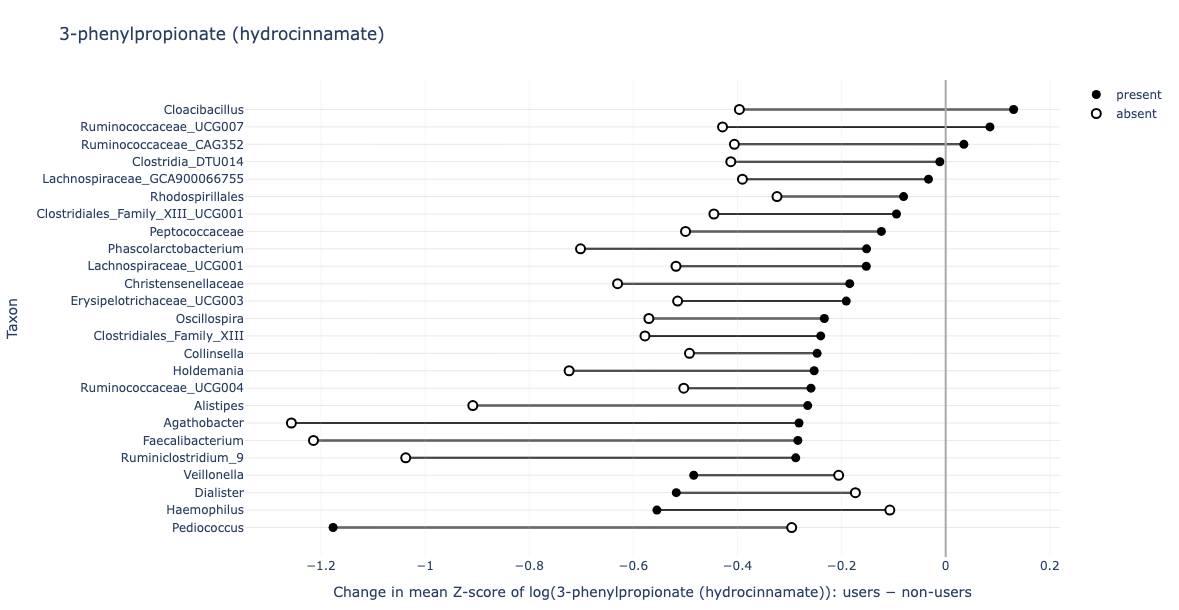

/users/cperez/miniconda3/envs/arivale-py/lib/python3.12/site-packages/plotly/io/_kaleido.py:510: DeprecationWarning:


Support for the 'engine' argument is deprecated and will be removed after September 2025.
Kaleido will be the only supported engine at that time.




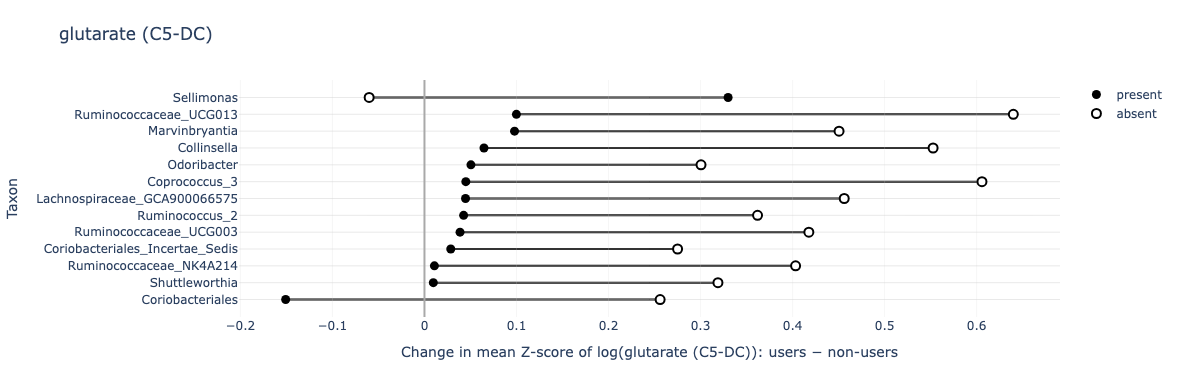

/users/cperez/miniconda3/envs/arivale-py/lib/python3.12/site-packages/plotly/io/_kaleido.py:510: DeprecationWarning:


Support for the 'engine' argument is deprecated and will be removed after September 2025.
Kaleido will be the only supported engine at that time.




/users/cperez/miniconda3/envs/arivale-py/lib/python3.12/site-packages/plotly/io/_kaleido.py:510: DeprecationWarning:


Support for the 'engine' argument is deprecated and will be removed after September 2025.
Kaleido will be the only supported engine at that time.




In [34]:
for microbe in microbes_barbell:
    make_barbell_plot(microbe, metabolites_microbes_pa_df, sig_interactions_pa)

In [35]:
# Glutarate
make_barbell_plot('metabolite_339', metabolites_microbes_pa_df, sig_interactions_pa)

/users/cperez/miniconda3/envs/arivale-py/lib/python3.12/site-packages/plotly/io/_kaleido.py:510: DeprecationWarning:


Support for the 'engine' argument is deprecated and will be removed after September 2025.
Kaleido will be the only supported engine at that time.




### Point plots for metabolites moderated by 10 taxa or less

In [ ]:
microbes_pointplot_df = sig_interactions_pa[sig_interactions_pa.metabolite.isin(microbes_pointplot)]

In [ ]:
pointplot_tuples = list(zip(microbes_pointplot_df.metabolite, microbes_pointplot_df.microbe))
len(pointplot_tuples)

In [ ]:
abx_year_pal = {0: "#007ea7", 1: 'red'}
line_order = ['-', '--']
x_labels = ['Absent','Present']
legend_labels = {'0': 'No', '1': 'Yes'}
markers_order = ["o","s"]
sns.set_style("whitegrid")
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(12, 12), constrained_layout=True)  
axes = axes.flatten()

for i, tuple_pair in enumerate(pointplot_tuples):
    sns.set_style("whitegrid")
    ax = axes[i]
    metab = pointplot_tuples[i][0]
    microbe = pointplot_tuples[i][1]
    get_metab_name = sig_interactions_pa[sig_interactions_pa['metabolite'] == metab]['CHEMICAL_NAME'].tolist()[0]
    get_plot_name = sig_interactions_pa[sig_interactions_pa['microbe'] == microbe]['plot_name'].tolist()[0]
    print(get_metab_name)
    if i == 0:
        sns.pointplot(data=metabolites_microbes_pa_df, x=microbe, y=metab,
                    linewidth=2, hue='abx_year', ms=5, capsize=0.01, linestyles=line_order,
                    palette=abx_year_pal,  markers=markers_order, dodge=0.01, legend=True, ax=ax)
        handles, labels = ax.get_legend_handles_labels()
        new_labels = [legend_labels.get(label, label) for label in labels] # Replace labels 
        ax.legend(handles, new_labels, title="Antibiotics in the last year")
        sns.move_legend(ax, "upper right") 
    else:
        sns.pointplot(data=metabolites_microbes_pa_df, x=microbe, y=metab,
                linewidth=2, hue='abx_year', ms=5, capsize=0.01, linestyles=line_order,
                palette=abx_year_pal, markers=markers_order, dodge=0.01, legend=False, ax=ax)
    current_positions = ax.get_xticks()
    ax.set_xticks(current_positions, labels=x_labels)
    ax.set_xlabel(f'{get_plot_name}')
    ax.set_ylabel(f'log({get_metab_name}) Z-score')

plt.savefig("figures/microbe_metab_interactions_pointplots.pdf") 
plt.show()